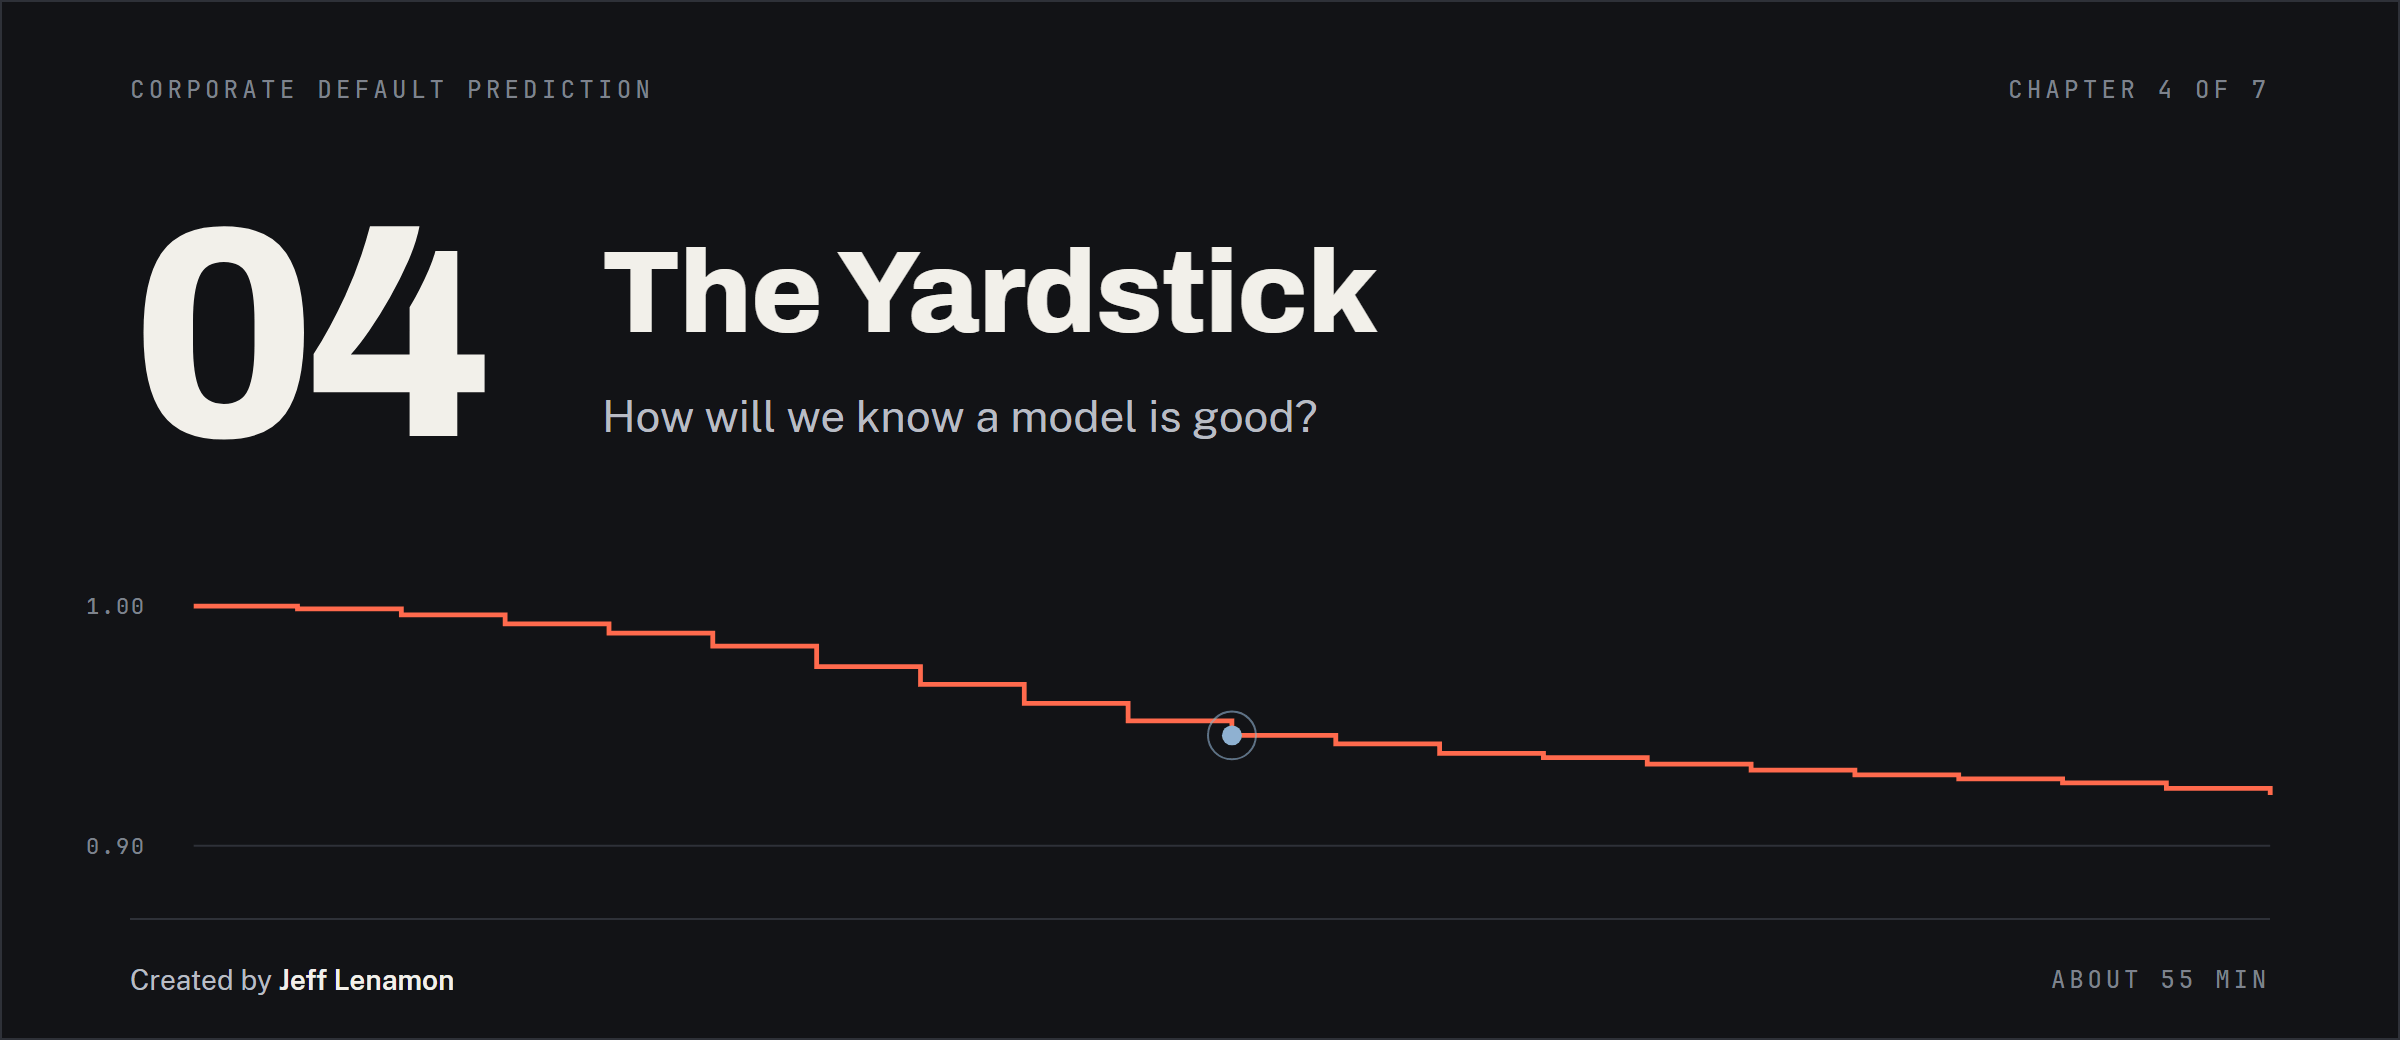

# Chapter 4: The Yardstick

How to test a default model so that its score can be believed, and what the classic scores earn under that test.

> This casebook is educational content created in a personal capacity

> Nothing here is investment advice or a recommendation to buy or sell any security

> The data is a public research dataset with anonymized company names

## The Question

Chapter 3 found where failure shows in the accounts.
The next chapters build models on it, and each will claim to beat the one before.

A claim like that is only as good as the test behind it.
How will we know a model is good?

## What You Will Learn

By the end you can:

- split the data by time, with a gap as long as the label looks ahead;
- keep every fitted number, down to a clipping bound, inside the training rows;
- score a ranking the way a credit desk uses it;
- put an interval on a score, and on the difference between two scores;
- measure a classic score, refit it, and compare the first three models.

## What You Need

Chapter 3, which wrote the `features` table this chapter reads.
Chapter 2 explains the label, and Chapter 3 the ratios and the Wilson interval.

The chapter writes the out-of-fold scores of its three models, and a record of how each one is built.

## Your Route

![Your route through Chapter 4: 1 Setting Up, 4 minutes; 2 Time Is the Only Honest Split, 4 minutes; 3 The Embargo, 1 minute; 4 Walking Forward, 2 minutes; 5 Preprocessing Inside the Fold, 2 minutes; 6 Ranking Metrics, 2 minutes; 7 The Unit of a Credit Desk, 4 minutes; 8 How Sure Are We?, 4 minutes; 9 Altman's Z, 6 minutes; 10 Refitting Z, 5 minutes; 11 The Scoreboard So Far, 7 minutes.](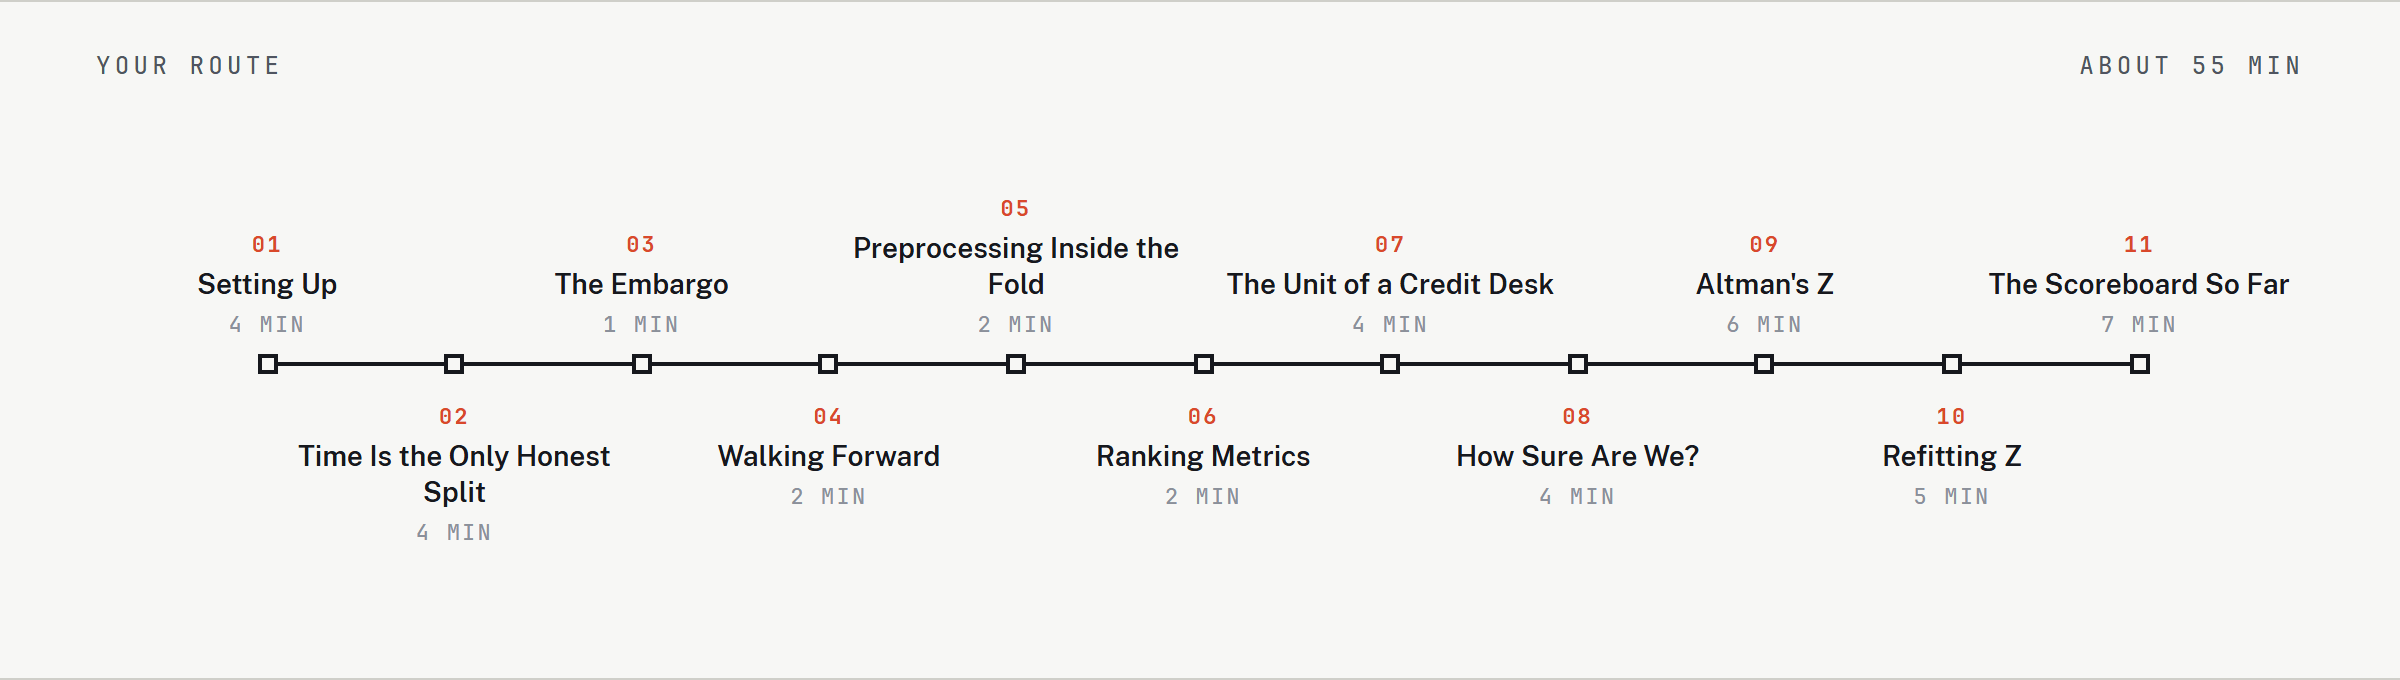)

**Time.** About 44 minutes to read and run, then about 9 for Your Turn.

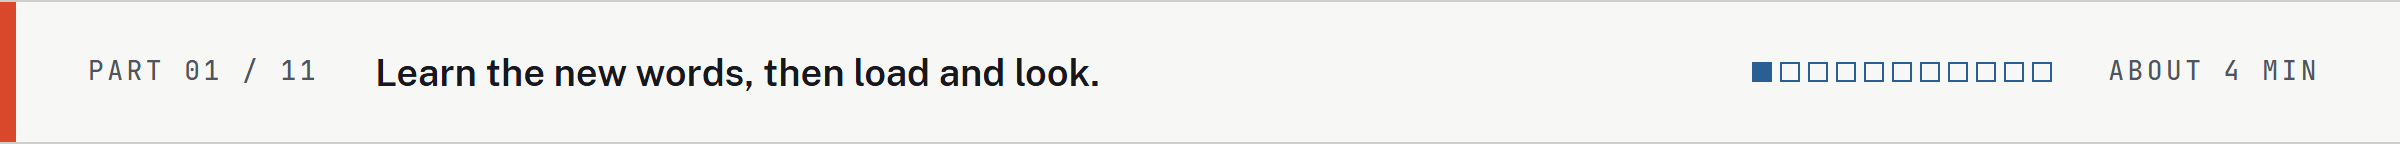

# Setting Up

Make sure the Jupyter kernel `corp-default` is selected before you run a cell.
If it is not in the list, or an import fails, the [Quick Start](../README.md#quick-start) shows how to register it and refresh the list.

## The Data Dictionary

The chapter reads `features`: the labeled firm-years with the 24 ratios and 21 history columns of Chapter 3, and the SIC `division` of Chapter 1.
It adds no input.

What it builds is a table of **out-of-fold scores**, one row for each firm-year a model is tested on.

| Column | What it is |
| --- | --- |
| `company_name`, `year`, `target` | The firm-year and its label, as before |
| `score` | What the model says about the row, where higher means riskier |
| `pct` | The score's **percentile** among the scores of the same year, from 0 to 1 |
| `model` | Which model gave the score |

Four terms come back in every later chapter.

| Term | What it means |
| --- | --- |
| **Training rows** | The rows a model is fitted on |
| **Validation rows** | Rows the model has not seen, on which it is scored |
| **Fold** | One pairing of training rows with validation rows |
| **Out of fold** | Scored by a model that did not train on the row |

Q. What gets imported and loaded?

In [1]:
from collections.abc import Callable, Iterator

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator, MultipleLocator, PercentFormatter
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer, StandardScaler

from corp_default import store, viz
from corp_default.classic import ALTMAN_ZONES, altman_z2, altman_zone
from corp_default.evaluate import (
    BUDGETS,
    KEYS,
    SEED,
    fold_table,
    paired_table,
    scoreboard,
    walk_forward_oof,
)
from corp_default.features import FAMILIES, feature_names
from corp_default.metrics import (
    accuracy_ratio,
    trapezoid_pr_auc,
    wilson_interval,
    within_year_percentile,
)
from corp_default.splits import (
    CRISIS_FOLDS,
    DEV_END,
    FOLD_YEARS,
    HOLDOUT,
    HORIZON,
    Fold,
    SealedHoldoutError,
    holdout,
)

store.open_chapter(4)
viz.use_house_style()
SOURCE = "Lombardo et al. (2022), Kaggle copy"
OOF_SOURCE = f"{SOURCE}; out-of-fold rows, {FOLD_YEARS[0]} to {FOLD_YEARS[-1]}"

features = store.load_frame("features")

**Reading.** The table of Chapter 3 is in memory, and the house style is set for every chart.

Q. What does the table look like?

In [2]:
features.head()

,company_name,status_label,year,current_assets,cogs,depreciation_amort,ebitda,inventory,net_income,total_receivables,...,d2_mve_to_liabilities,d2_ebitda_margin,d2_ebitda_to_assets,g2_sales,g2_assets,g2_market_cap,loss_2y_ago,years_observed,division,major_group
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,D,37
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,D,37
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,...,-0.016874,-0.044320,-0.081841,-0.472329,-0.042453,-0.022132,0.0,3,D,37
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,...,-0.676815,-0.022919,-0.046933,-0.365936,-0.021943,-0.967412,0.0,4,D,37
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,...,-0.153711,0.030248,0.028647,0.020512,-0.001278,-0.165741,1.0,5,D,37


**Reading.** Each row is a firm-year: its dollar items, its label, then the ratios and the history.

Q. How large is the table, and what does each column hold?

In [3]:
RATIOS = [name for members in FAMILIES.values() for name in members]

store.put("rows", len(features))
store.put("n_ratios", len(RATIOS))
store.put("n_history", len(feature_names()) - len(RATIOS))
store.put("dev_end", DEV_END)
store.put("holdout_first", HOLDOUT[0])
store.put("holdout_last", HOLDOUT[1])

print(features.shape)
features.info()

(72393, 73)
<class 'pandas.DataFrame'>
RangeIndex: 72393 entries, 0 to 72392
Data columns (total 73 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   company_name                        72393 non-null  str    
 1   status_label                        72393 non-null  str    
 2   year                                72393 non-null  int64  
 3   current_assets                      72393 non-null  float64
 4   cogs                                72393 non-null  float64
 5   depreciation_amort                  72393 non-null  float64
 6   ebitda                              72393 non-null  float64
 7   inventory                           72393 non-null  float64
 8   net_income                          72393 non-null  float64
 9   total_receivables                   72393 non-null  float64
 10  market_cap                          72393 non-null  float64
 11  net_sales                           7239

**Reading.** The table has 72,393 rows.
The columns with blanks are `debt_to_ebitda`, which needs a positive EBITDA, and the history columns, which need an earlier year.

Q. What do the year and the label hold?

In [4]:
features[["year", "target", "years_observed"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
year,72393.0,2006.710,5.213,1999.0,2002.0,2006.0,2011.0,2016.0
target,72393.0,0.016,0.124,0.0,0.0,0.0,0.0,1.0
years_observed,72393.0,6.750,4.776,1.0,3.0,6.0,10.0,18.0


**Reading.** The years and the base rate are those of Chapter 3.
Nothing in this chapter changes an input: it builds the test that every model has to pass.

**Next, which rows a model may be tested on.**

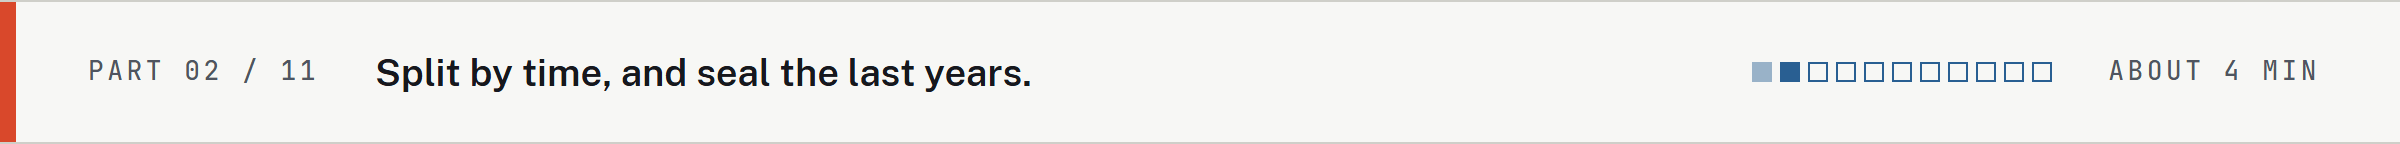

# Time Is the Only Honest Split

A model is tested on rows it did not train on.
Which rows to set aside is the first decision, and the one that most often goes wrong.

A lender uses a model on years that have not happened yet.
So the test rows must come after the training rows, and that fixes the layout of the whole casebook.

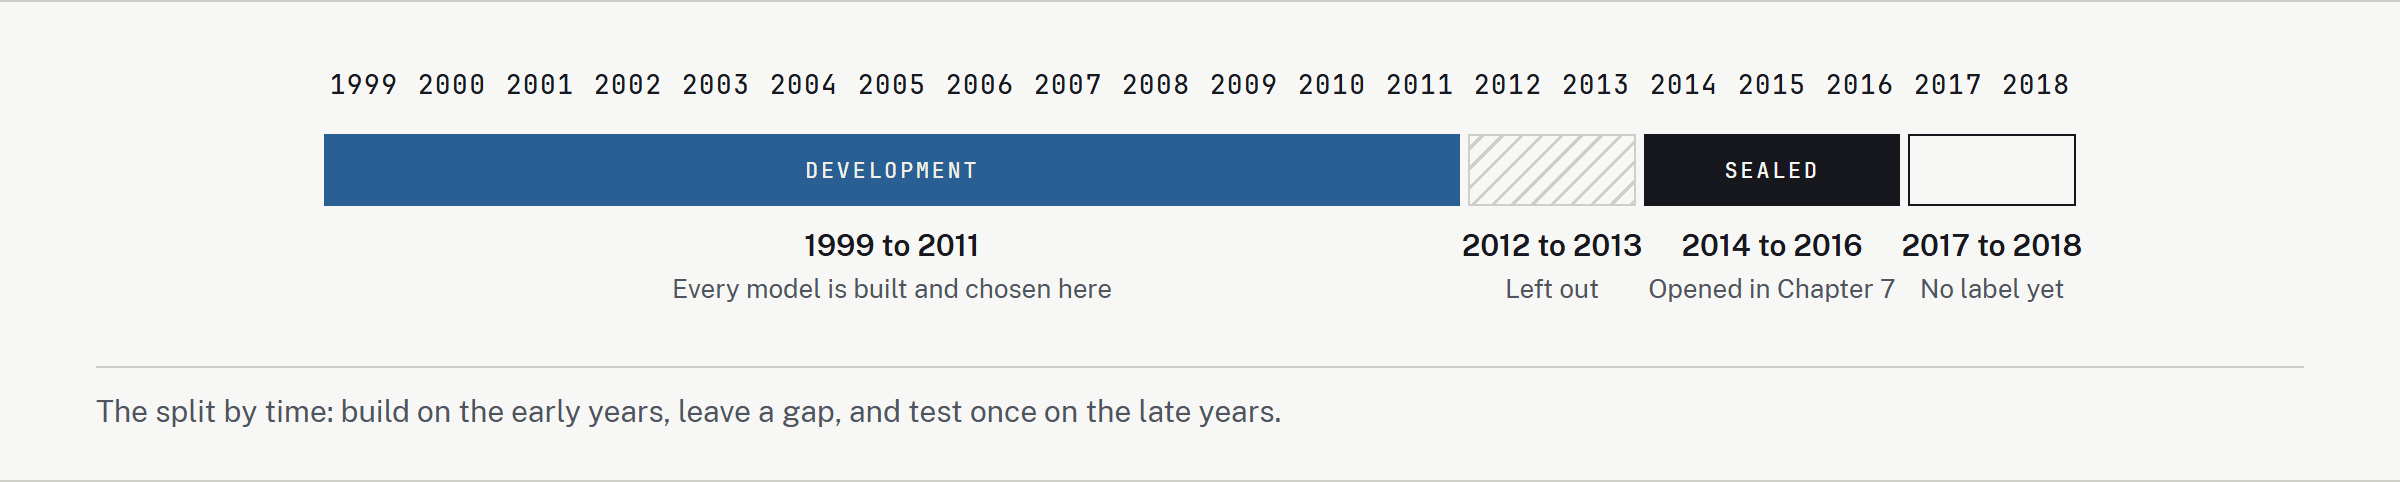

The **development years** run to 2011: every model is built, tuned, and chosen there.
The years 2014 to 2016 are the **holdout**, sealed until Chapter 7 opens them once.

Q. How does the library keep to that?

In [5]:
# taught: corp_default.splits.development
def development(frame: pd.DataFrame) -> pd.DataFrame:
    """Fiscal years up to DEV_END: everything a model may be built and chosen on."""
    return frame.loc[frame["year"] <= DEV_END]

Q. What happens when a chapter reaches for the holdout early?

In [6]:
dev = development(features).reset_index(drop=True)

try:
    holdout(features)
except SealedHoldoutError as refusal:
    print("holdout(features):", refusal)

sealed = features["year"].between(*HOLDOUT)
store.put("dev_rows", len(dev))
store.put("dev_positives", int(dev["target"].sum()))
store.put("sealed_rows", int(sealed.sum()))

pd.Series(
    {
        f"development, to {DEV_END}": len(dev),
        f"left out, {DEV_END + 1} to {HOLDOUT[0] - 1}": int((~sealed).sum()) - len(dev),
        f"sealed, {HOLDOUT[0]} to {HOLDOUT[1]}": int(sealed.sum()),
    },
    name="rows",
).to_frame()

holdout(features): the 2014 to 2016 holdout is sealed until Chapter 7 opens it


,rows
"development, to 2011",55524
"left out, 2012 to 2013",6915
"sealed, 2014 to 2016",9954


**Reading.** The function refuses.
The development years hold 55,524 rows and 840 positives, and 9,954 rows wait behind the seal.

The common shortcut is to hold out rows at random.
It lets a model train on a company's later row and be tested on its earlier one.

**Predict 1.** A model is tested twice on the rows of 2008 to 2011.
Once it trains on a random four fifths of all development rows, and once on the years to 2005 only. How far apart are the two scores?

The score is the ROC-AUC of Chapter 2, taken on each row's rank within its own year.
Two models are tried, both on the 24 ratios.

Q. What does a random split do to the score?

In [7]:
EARLY, LATE = 2005, 2008  # fit on fiscal years to EARLY, and score the years from LATE on
early, late = (dev["year"] <= EARLY).to_numpy(), (dev["year"] >= LATE).to_numpy()
models = {
    "Logistic regression": make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000)
    ),
    "Gradient-boosted trees": HistGradientBoostingClassifier(random_state=SEED),
}


def late_auc(scores: np.ndarray) -> float:
    """ROC-AUC on the late rows, with each score ranked within its own year."""
    ranked = within_year_percentile(pd.Series(scores, index=dev.index[late]), dev.loc[late, "year"])
    return roc_auc_score(dev.loc[late, "target"], ranked)


split = {}
for name, model in models.items():
    at_random = cross_val_predict(
        model,
        dev[RATIOS],
        dev["target"],
        cv=KFold(5, shuffle=True, random_state=SEED),
        method="predict_proba",
    )[:, 1]
    model.fit(dev.loc[early, RATIOS], dev.loc[early, "target"])
    by_time = model.predict_proba(dev.loc[late, RATIOS])[:, 1]
    split[name] = {
        "Rows held out at random": late_auc(at_random[late]),
        "Later years held out": late_auc(by_time),
    }
split = pd.DataFrame(split).T
# The reading says the random split trains on more rows than the early years hold. Checked here.
assert len(dev) * 4 / 5 > early.sum()

store.put("early_year", EARLY)
store.put("late_year", LATE)
store.put("trees_random", split.loc["Gradient-boosted trees", "Rows held out at random"])
store.put("trees_time", split.loc["Gradient-boosted trees", "Later years held out"])
store.put("logit_random", split.loc["Logistic regression", "Rows held out at random"])
store.put("logit_time", split.loc["Logistic regression", "Later years held out"])

split.round(3)

,Rows held out at random,Later years held out
Logistic regression,0.750,0.739
Gradient-boosted trees,0.798,0.718


**Reading.** The trees score 0.798 on rows held out at random and 0.718 on later years.
The logistic regression moves less, from 0.750 to 0.739, because a stiffer model has less room to memorize.

The random split also trains on more rows than the years to 2005 hold, so not all of the gap is memory.

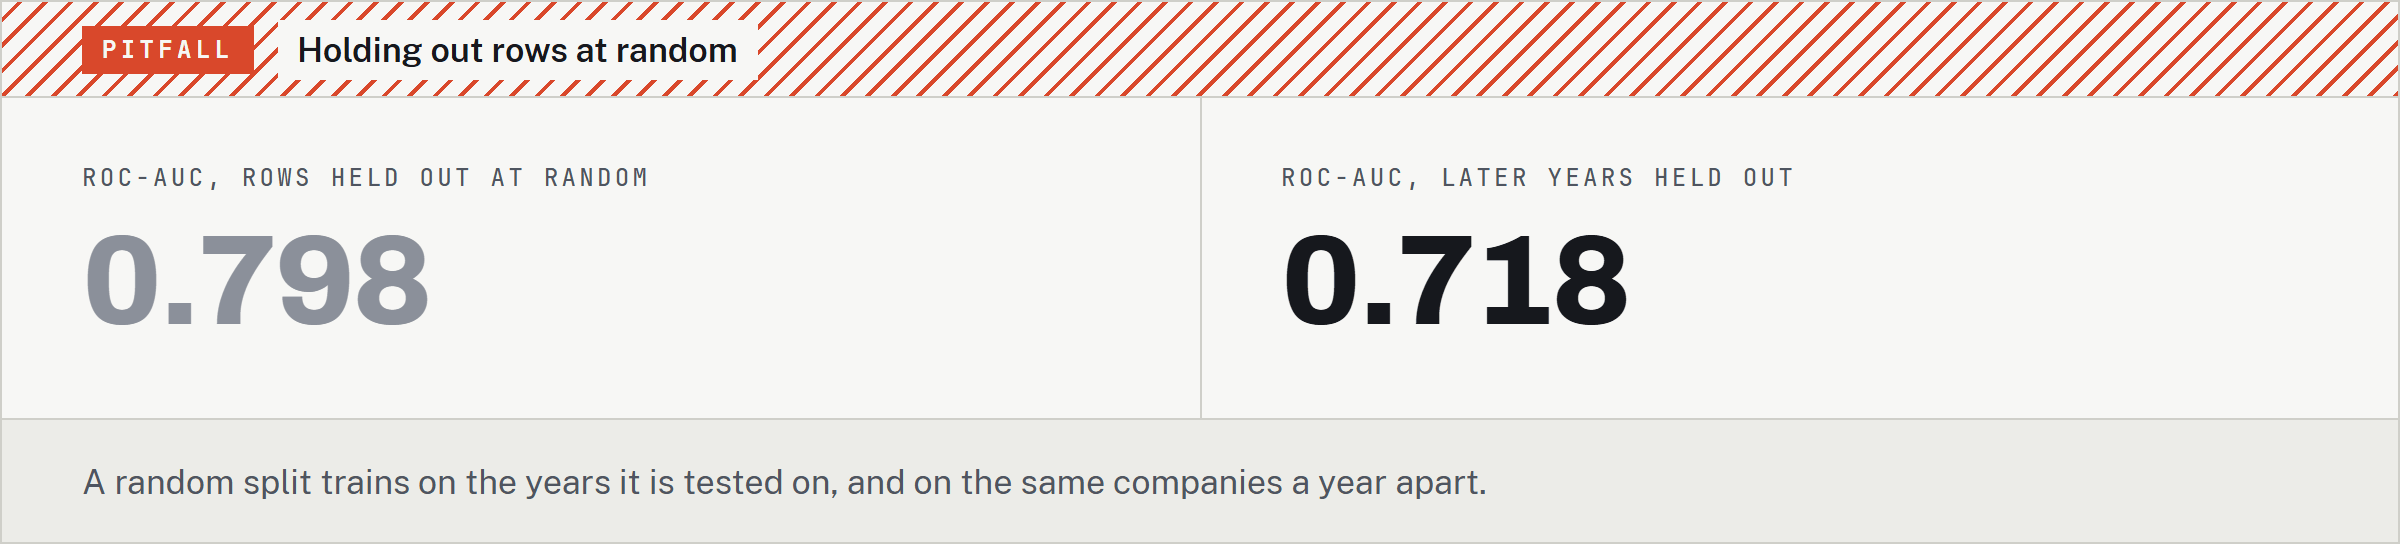

**Check.** The random split showed the trees two things a lender would not have. Name them.

<details>
<summary>Show the answer</summary>

The first is the same company a year earlier or later.
Accounts change slowly, so the model recognizes the company and repeats its label.

The second is the test years themselves.
A model that trained on other rows of a bad year has learned that the year was bad.

</details>

**Next, why a split by time still needs a gap.**

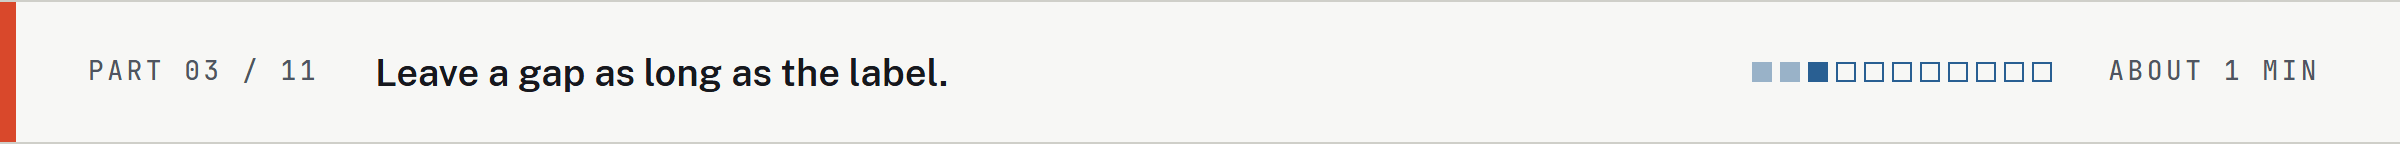

# The Embargo

A split by time is not yet enough.
The label of a row looks two years ahead.

So a row from just before a test year carries, inside its label, news from the test period.

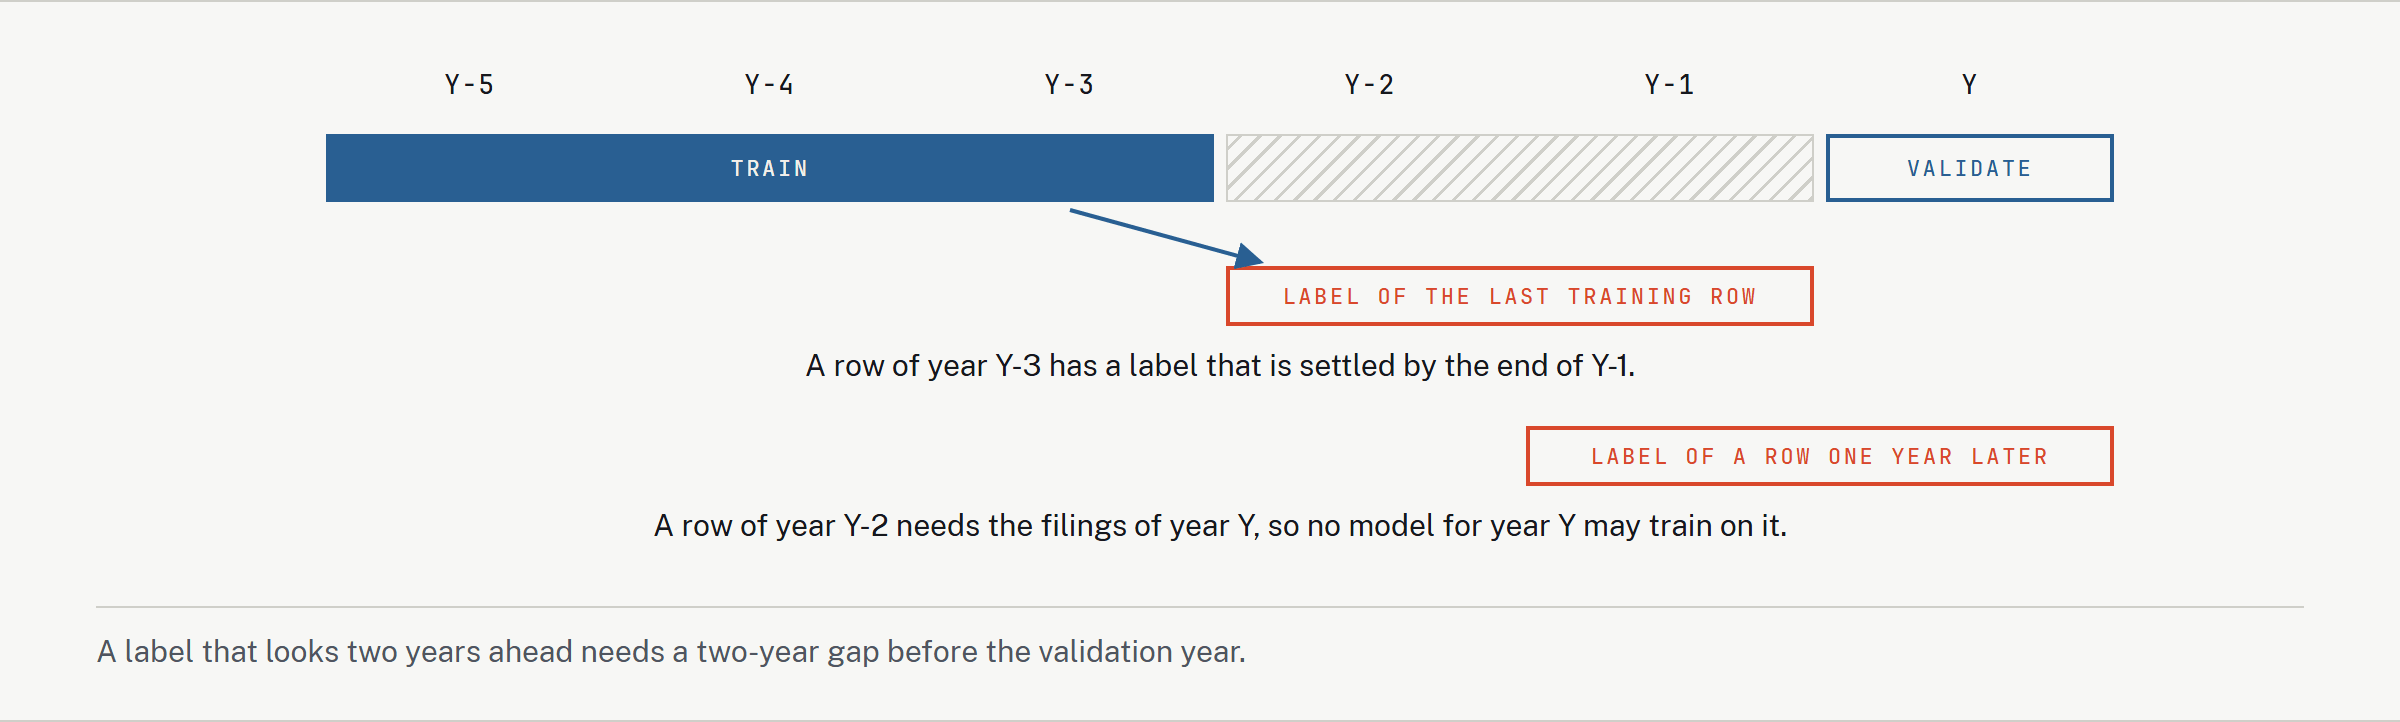

The gap between the last training year and the first test year is the **embargo**.
It is as long as the label looks ahead.

Q. How much would leak without it?

In [8]:
positive = features.loc[features["target"] == 1]
gap_year = DEV_END + 1
in_gap_year = set(positive.loc[positive["year"] == gap_year, "company_name"])
year_before = set(positive.loc[positive["year"] == DEV_END, "company_name"])
# The label of the last development row is settled before the first sealed year.
assert DEV_END + HORIZON < HOLDOUT[0]

store.put("gap_year", gap_year)
store.put("gap_positives", len(in_gap_year))
store.put("gap_shared", len(in_gap_year & year_before))

pd.Series(
    {
        f"positive rows of {gap_year}": len(in_gap_year),
        f"of them, positive in {DEV_END} too": len(in_gap_year & year_before),
    },
    name="rows",
).to_frame()

,rows
positive rows of 2012,58
"of them, positive in 2011 too",26


**Reading.** Of the 58 positive rows of 2012, 26 belong to companies that are positive in 2011 too.
It is the same failure, seen one year earlier.

A test on 2012 would reward a model for remembering them.
So the two years after 2011 are left out, and the cell asserts that the last development label is settled before the first sealed year.

**Next, a test that can be used more than once.**

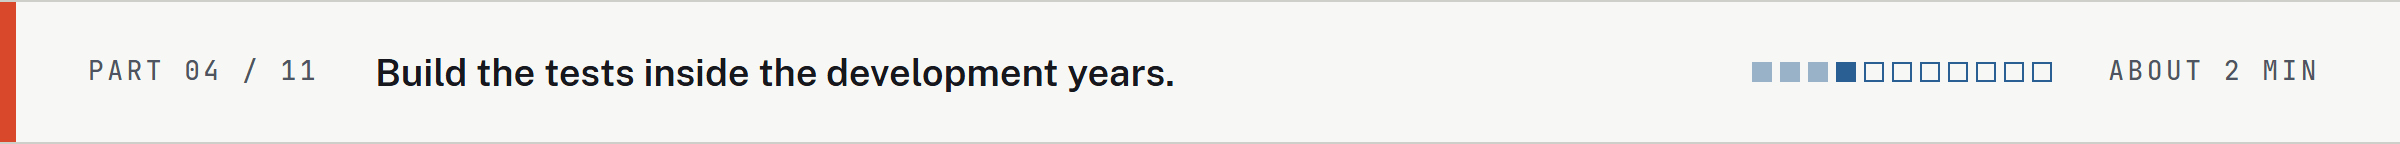

# Walking Forward

The holdout can be opened once.
Every choice before then, of a model or of a setting, needs a test of its own inside the development years.

A **walk-forward** gives one.
For each validation year from 2005 to 2011, a model trains on the years up to three before it and scores that year.

Q. How does the library build the folds?

In [9]:
# taught: corp_default.splits.walk_forward_folds
def walk_forward_folds(
    frame: pd.DataFrame, horizon: int = HORIZON, fold_years: tuple[int, ...] = FOLD_YEARS
) -> list[Fold]:
    """One fold per validation year Y: train on years up to Y - horizon - 1, validate on Y.

    Every training label resolves within `horizon` years, so it is known before Y begins.
    """
    return [
        Fold(
            year=year,
            train=frame.index[frame["year"] <= year - horizon - 1],
            valid=frame.index[frame["year"] == year],
        )
        for year in fold_years
    ]

Q. What is in each fold?

In [10]:
folds = walk_forward_folds(dev)
rows = []
for fold in folds:
    train, valid = dev.loc[fold.train], dev.loc[fold.valid]
    # The embargo holds: every training label is settled before the validation year.
    assert train["year"].max() + HORIZON < fold.year
    rows.append(
        {
            "validation year": fold.year,
            "trains on years to": int(train["year"].max()),
            "training rows": len(train),
            "training positives": int(train["target"].sum()),
            "validation rows": len(valid),
            "validation positives": int(valid["target"].sum()),
            "crisis fold": fold.year in CRISIS_FOLDS,
        }
    )
fold_rows = pd.DataFrame(rows).set_index("validation year")

store.put("n_folds", len(folds))
store.put("first_fold", folds[0].year)
store.put("last_fold", folds[-1].year)
store.put("oof_rows", int(fold_rows["validation rows"].sum()))
store.put("oof_positives", int(fold_rows["validation positives"].sum()))
store.put("first_train_rows", fold_rows["training rows"].iloc[0])
store.put("first_train_positives", fold_rows["training positives"].iloc[0])
store.put("last_train_rows", fold_rows["training rows"].iloc[-1])
store.put("n_crisis_folds", int(fold_rows["crisis fold"].sum()))
store.put(
    "crisis_positives", int(fold_rows.loc[fold_rows["crisis fold"], "validation positives"].sum())
)

fold_rows

,trains on years to,training rows,training positives,validation rows,validation positives,crisis fold
validation year,,,,,,
2005,2002,20045,155,4165,105,True
2006,2003,24433,239,4077,114,True
2007,2004,28735,328,3950,79,True
2008,2005,32900,433,3799,57,False
2009,2006,36977,547,3720,59,False
2010,2007,40927,626,3590,47,False
2011,2008,44726,683,3488,51,False


**Reading.** The 7 folds hold 26,789 validation rows and 512 positives.
The first trains on 20,045 rows with 155 positives, which is thin, and the last on 44,726.

Of the folds, 3 are **crisis folds**: their two-year windows reach the last filings before the bankruptcies of the 2007 to 2009 recession.
The rule that marks them sits in the library, fixed before any model is scored, and they hold 298 of the positives.

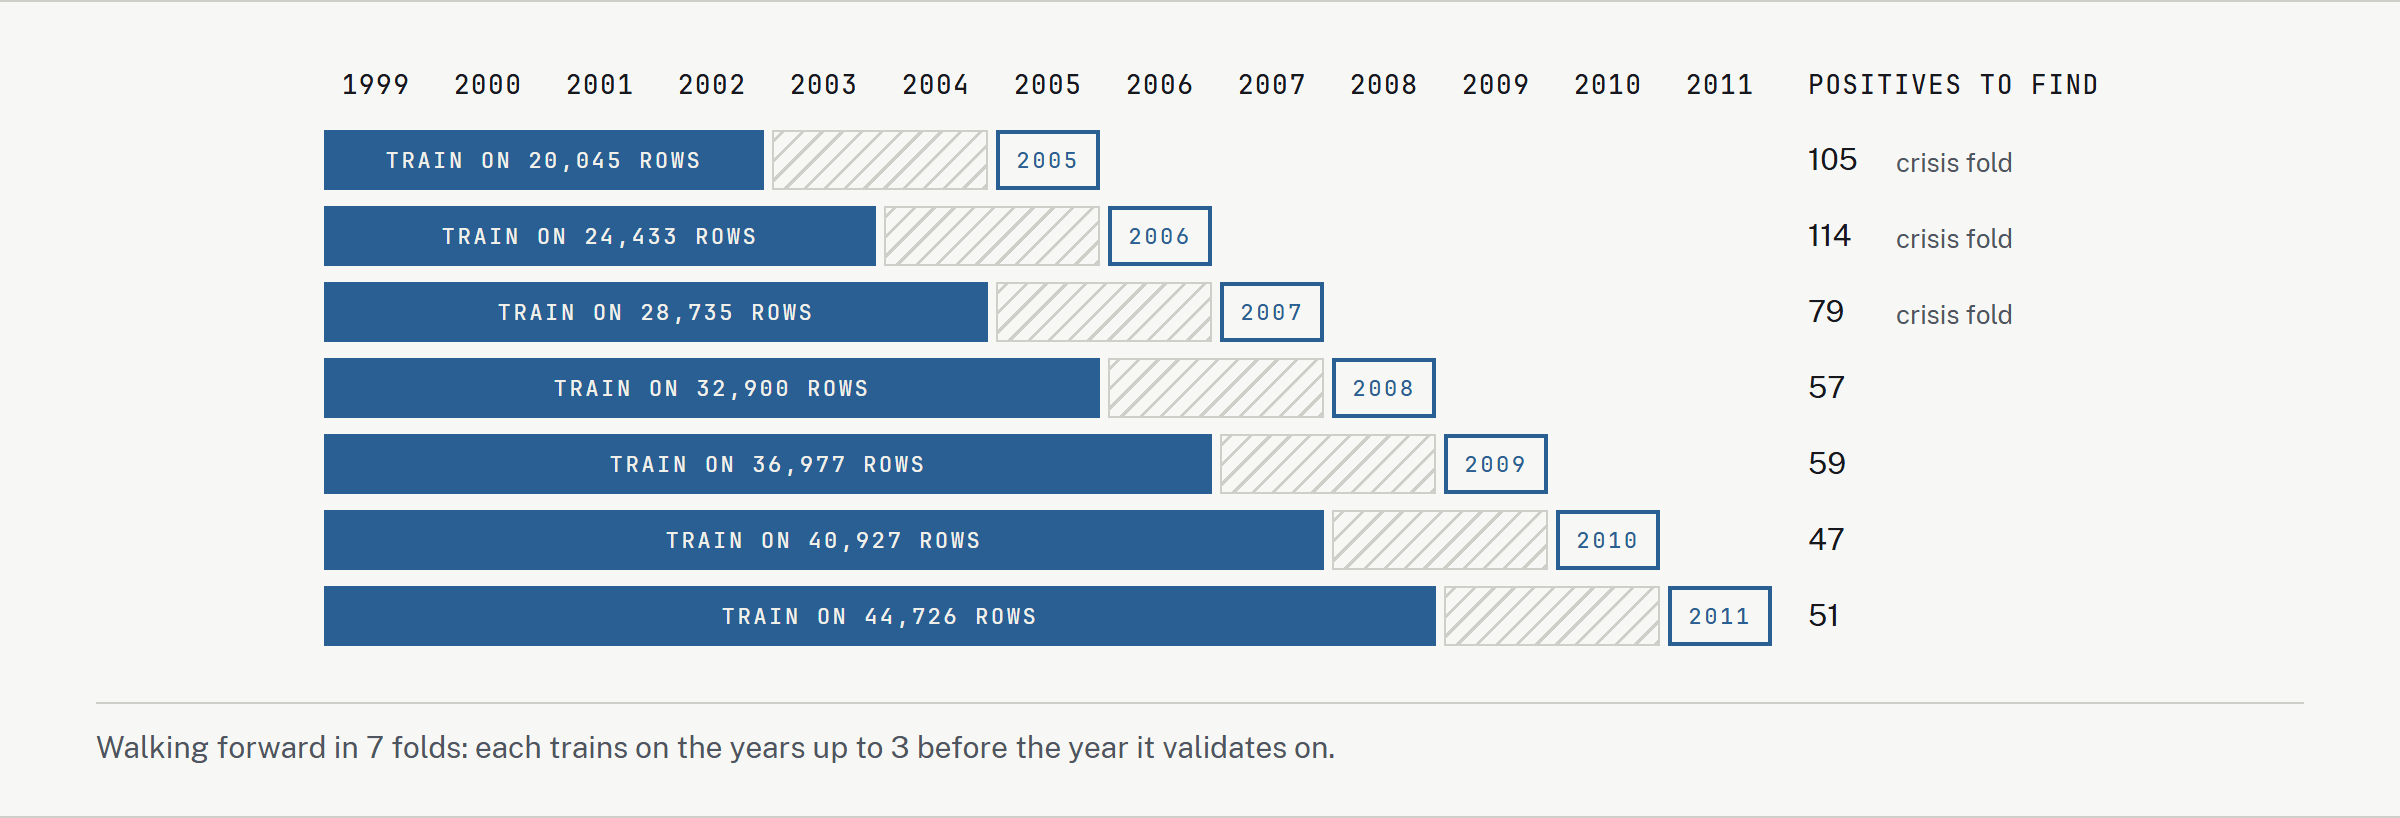

Each fold has its own model, so its scores are on a scale of their own.
A desk also ranks the companies of one year against each other, not against other years.

So every score becomes its percentile within its year, `pct`, and the percentiles of all folds are pooled.

**Next, the numbers a model's inputs are prepared with.**

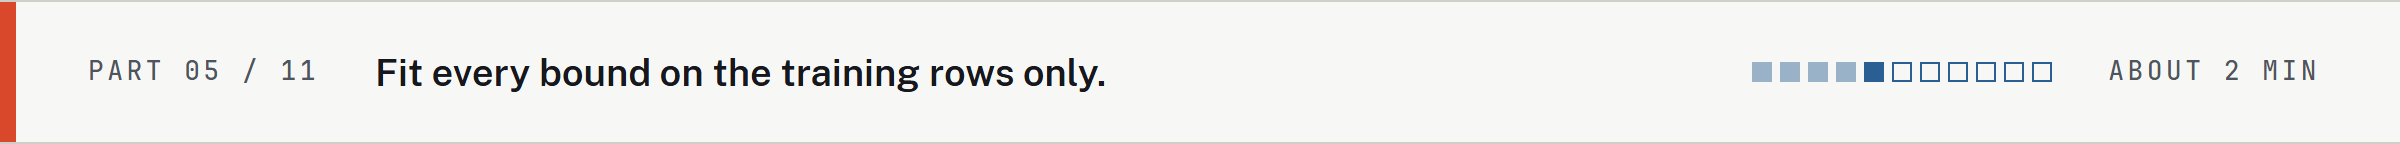

# Preprocessing Inside the Fold

Chapter 3 showed ratios with extreme tails.
Before a linear model sees a ratio it is clipped at a low and a high percentile, which is called **winsorizing**, and a blank is filled with the median.

The bounds and the medians are fitted to data, as a model's weights are.
If they are fitted on every row, the validation rows have shaped the model's inputs.

Q. How does the library fit them?

In [11]:
# taught: corp_default.features.fit_prepare
def fit_prepare(
    train: pd.DataFrame, cols: list[str], impute: bool = True
) -> tuple[Callable[[pd.DataFrame], pd.DataFrame], pd.Series, pd.Series, pd.Series]:
    """Winsorization bounds at the 1st and 99th percentiles and fill medians, from `train` only.

    impute=False leaves missing values in place for tree models, which route them themselves.
    """
    lower = train[cols].quantile(0.01)
    upper = train[cols].quantile(0.99)
    medians = train[cols].clip(lower, upper, axis=1).median()

    def prepare(frame: pd.DataFrame) -> pd.DataFrame:
        clipped = frame[cols].clip(lower, upper, axis=1)
        return clipped.fillna(medians) if impute else clipped

    return prepare, lower, upper, medians

The function hands back another function, and that one carries the bounds of the training rows wherever it goes.

Q. What do bounds from the training rows cost on the validation rows?

In [12]:
CONTINUOUS = [name for name in RATIOS if name not in ("no_lt_debt", "negative_ebitda")]


def beyond(frame: pd.DataFrame, low: pd.Series, high: pd.Series) -> float:
    """Share of the ratio values of `frame` that lie outside the bounds, and so are clipped."""
    return float(((frame[CONTINUOUS] < low) | (frame[CONTINUOUS] > high)).to_numpy().mean())


_, low_all, high_all, _ = fit_prepare(dev, CONTINUOUS)  # the leak: bounds that have seen every year
clipped = {}
for fold in folds:
    train, valid = dev.loc[fold.train], dev.loc[fold.valid]
    _, low, high, _ = fit_prepare(train, CONTINUOUS)
    clipped[fold.year] = {
        "training values": beyond(train, low, high),
        "validation values, bounds from training rows": beyond(valid, low, high),
        "validation values, bounds from every row": beyond(valid, low_all, high_all),
    }
clipped = pd.DataFrame(clipped).T
clipped.index.name = "validation year"

store.put("clipped_train", clipped["training values"].iloc[-1])
store.put("clipped_honest", clipped["validation values, bounds from training rows"].iloc[-1])
store.put("clipped_leak", clipped["validation values, bounds from every row"].iloc[-1])
store.put("clipped_first", clipped["validation values, bounds from training rows"].iloc[0])

clipped.round(4)

,training values,"validation values, bounds from training rows","validation values, bounds from every row"
validation year,,,
2005,0.0185,0.0190,0.0159
2006,0.0185,0.0207,0.0180
2007,0.0185,0.0203,0.0180
2008,0.0185,0.0243,0.0217
2009,0.0185,0.0238,0.0216
2010,0.0185,0.0242,0.0220
2011,0.0185,0.0271,0.0253


**Reading.** The bounds clip 1.9% of the training values, as they are built to.
On the validation rows they clip more, and more as the years pass: 1.9% in the first fold and 2.7% in the last.

The companies have grown since the training years, so more of them lie beyond bounds set in the past.
Bounds fitted on every row would clip 2.5% in the last fold.

The leak is small here.
It is still a leak, and keeping it out costs one line of code.

**Next, how to put a number on a ranking.**

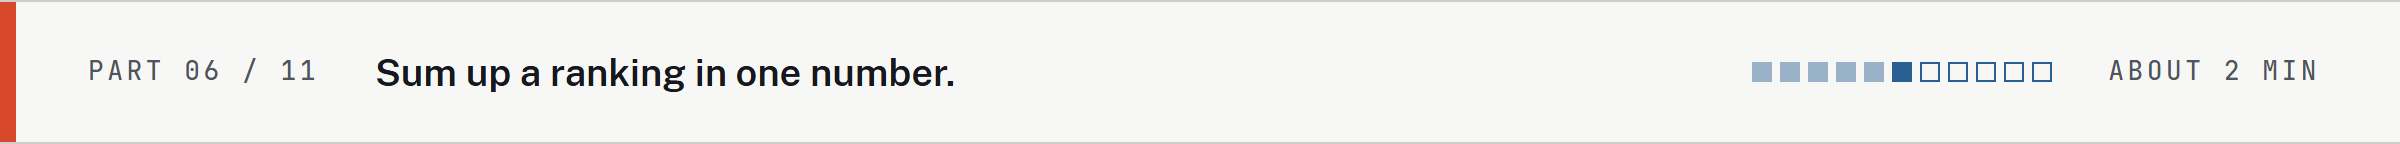

# Ranking Metrics

A default model has one job, which is to rank: the companies most likely to fail come first.
The simplest ranking uses one ratio, and the next three parts use leverage, `liabilities_to_assets`, so that the yardstick is ready before any model is.

Three numbers sum up a ranking:

- the **ROC-AUC**, the chance that a positive row outranks a negative one;
- the **accuracy ratio**, twice the ROC-AUC less one, so that a coin scores zero and a perfect ranking one;
- the **average precision**, the mean over the positive rows of the share of positives among the rows ranked at or above each.

Q. How does leverage score in each fold?

In [13]:
leverage = walk_forward_oof(lambda train, valid: valid["liabilities_to_assets"], dev, folds)
y, pct = leverage["target"].to_numpy(), leverage["pct"].to_numpy()


def ranking(rows: pd.DataFrame) -> pd.Series:
    """The base rate of the rows, and two measures of how well `pct` ranks them."""
    return pd.Series(
        {
            "base rate": rows["target"].mean(),
            "ROC-AUC": roc_auc_score(rows["target"], rows["pct"]),
            "average precision": average_precision_score(rows["target"], rows["pct"]),
        }
    )


by_fold = leverage.groupby("year").apply(ranking, include_groups=False)
# The reading says the fold with the highest base rate has the highest average precision,
# and not the highest ROC-AUC. Checked here.
assert by_fold["average precision"].idxmax() == by_fold["base rate"].idxmax()
assert by_fold["ROC-AUC"].idxmax() != by_fold["base rate"].idxmax()

GRADES = 10  # a rating scale: the percentile cut into this many grades
graded = np.ceil(pct * GRADES)

store.put("leverage_auc", roc_auc_score(y, pct))
store.put("leverage_ar", accuracy_ratio(y, pct))
store.put("leverage_ap", average_precision_score(y, pct))
store.put("oof_base", y.mean())
store.put("ap_top_year", int(by_fold["average precision"].idxmax()))
store.put("ap_top", by_fold["average precision"].max())
store.put("ap_low", by_fold["average precision"].min())
store.put("grades", GRADES)
store.put("trapezoid_fine", trapezoid_pr_auc(y, pct))
store.put("trapezoid_graded", trapezoid_pr_auc(y, graded))
store.put("ap_graded", average_precision_score(y, graded))

by_fold.loc["all folds"] = ranking(leverage)
by_fold.round(4)

,base rate,ROC-AUC,average precision
year,,,
2005,0.0252,0.6364,0.0470
2006,0.0280,0.6863,0.0588
2007,0.0200,0.7469,0.0501
2008,0.0150,0.6495,0.0291
2009,0.0159,0.6785,0.0320
2010,0.0131,0.7781,0.0384
2011,0.0146,0.6558,0.0257
all folds,0.0191,0.6856,0.0385


**Reading.** Over all folds leverage has a ROC-AUC of 0.686, an accuracy ratio of 0.371, and an average precision of 0.0385.
A random ranking has an average precision equal to the base rate, 0.0191, so the number means little alone.

It also moves with the base rate, from 0.026 to 0.059 across the folds.
The fold of 2006 has the highest base rate and the highest average precision, and not the highest ROC-AUC.
So average precision compares models on the same rows, and never one year with another.

One trap sits beside it.
The area under the precision-recall curve is often computed by joining its points with straight lines, and the [scikit-learn guide](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html) warns that this can be too optimistic.

On leverage as it stands, the straight lines give 0.0383, close to the average precision.
Cut the same ranking into 10 grades, as a rating scale does, and the two part company.

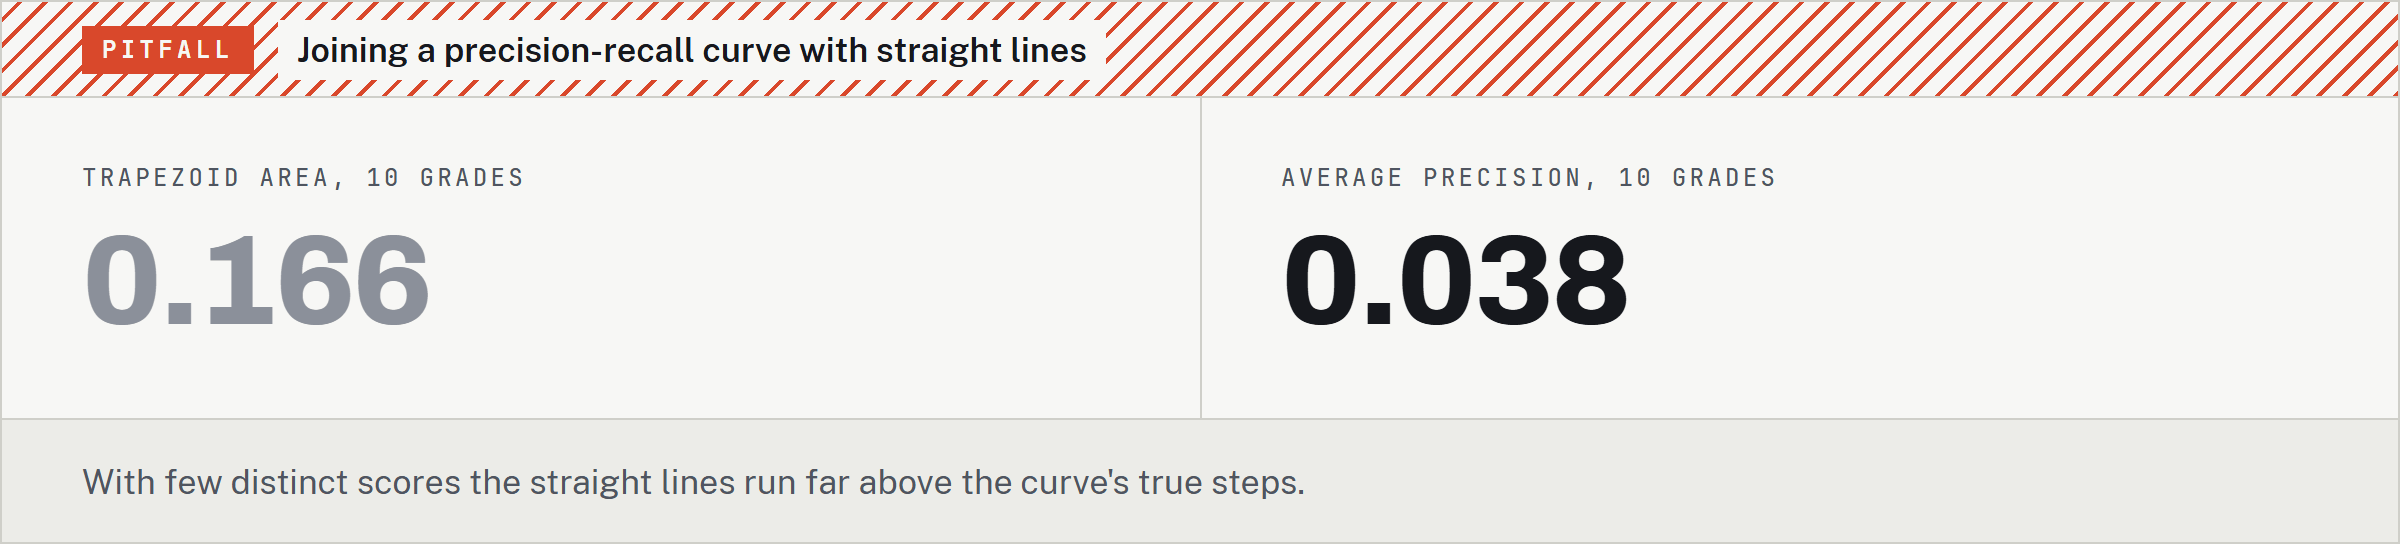

**Next, the measure a credit desk works with.**

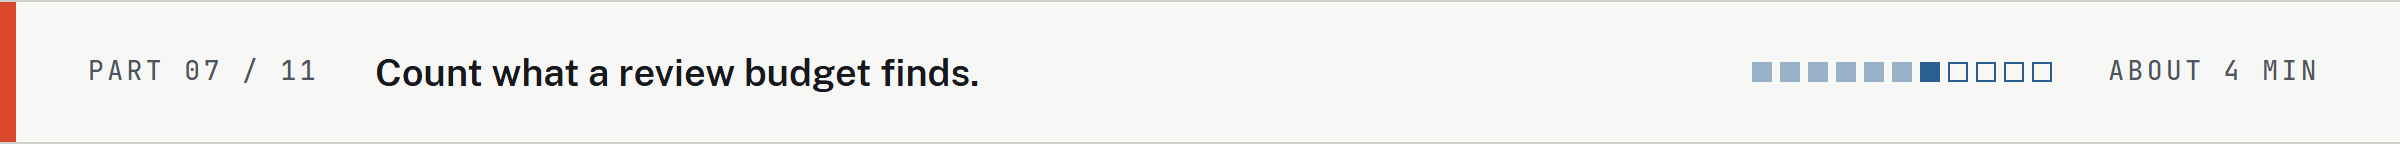

# The Unit of a Credit Desk

A desk cannot review every company.
It reviews the firm-years a model ranks worst, up to a **budget**, and the casebook uses budgets of 1%, 5%, and 10% of each year's firm-years.

The **capture rate** is the share of all the failures that fall inside the budget.

Q. How does the library count what a budget finds?

In [14]:
# taught: corp_default.metrics.capture_rate
def capture_rate(y_true, scores, budgets=(0.01, 0.05, 0.10)) -> pd.DataFrame:
    """Share of positives caught when the top `budget` share of rows by score is reviewed."""
    y_true = np.asarray(y_true)
    ranked = y_true[np.argsort(-np.asarray(scores), kind="mergesort")]
    total_pos = ranked.sum()
    rows = []
    for budget in budgets:
        k = max(1, round(budget * len(ranked)))
        caught = ranked[:k].sum()
        rows.append(
            {
                "budget": f"{budget:.0%}",
                "n_reviewed": k,
                "defaults_caught": int(caught),
                "capture_rate": caught / total_pos,
                "precision": caught / k,
                "lift": (caught / k) / y_true.mean(),
            }
        )
    return pd.DataFrame(rows)

The function also gives the **lift**: how many times more failures the budget holds than a random pick of the same size.

Q. How does the library trace the capture at every budget?

In [15]:
# taught: corp_default.metrics.capture_curve
def capture_curve(y_true, scores) -> tuple[np.ndarray, np.ndarray]:
    """Share of rows reviewed against share of positives captured, from (0, 0) to (1, 1)."""
    y_true = np.asarray(y_true)
    ranked = y_true[np.argsort(-np.asarray(scores), kind="mergesort")]
    reviewed = np.arange(len(ranked) + 1) / len(ranked)
    captured = np.concatenate([[0.0], np.cumsum(ranked) / ranked.sum()])
    return reviewed, captured

That curve is the **cumulative accuracy profile**, the CAP of a credit textbook.
The accuracy ratio is the area between it and the diagonal, as a share of the same area for a perfect ranking.

Q. What does the curve of leverage look like?

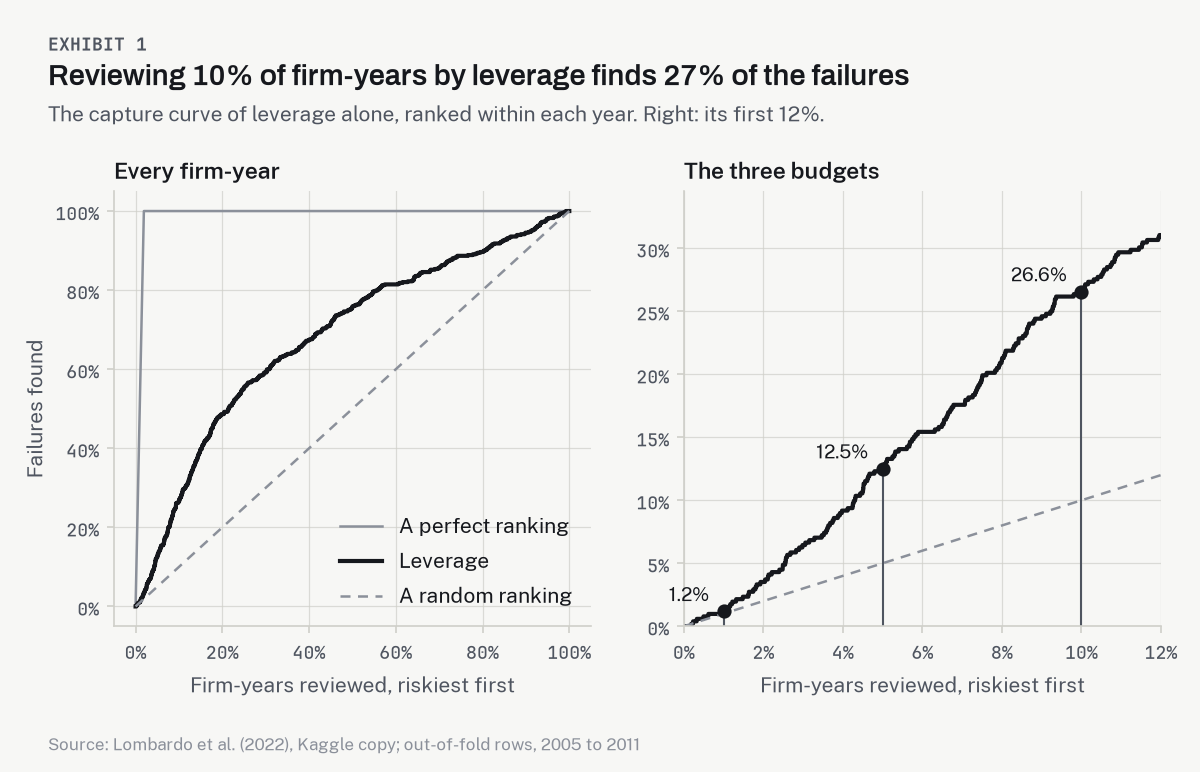

In [16]:
budgets = capture_rate(y, pct, BUDGETS).set_index("budget")
reviewed, captured = capture_curve(y, pct)
base = y.mean()

store.put("budgets", ", ".join(budgets.index[:-1]) + f", and {budgets.index[-1]}")
store.put("capture_10", budgets["capture_rate"].iloc[-1])
store.put("lift_10", budgets["lift"].iloc[-1])
store.put("capture_5", budgets["capture_rate"].iloc[1])
store.put("reviewed_1", budgets["n_reviewed"].iloc[0])
store.put("caught_1", budgets["defaults_caught"].iloc[0])
store.put("lift_1", budgets["lift"].iloc[0])

fig, (whole, top) = plt.subplots(1, 2, figsize=(viz.EXHIBIT_WIDTH_IN, 3.8))
whole.plot([0, base, 1], [0, 1, 1], color=viz.MIST, linewidth=1.2, label="A perfect ranking")
whole.plot(reviewed, captured, color=viz.INK, label="Leverage")
whole.plot([0, 1], [0, 1], color=viz.MIST, linewidth=1.2, linestyle=(0, (4, 3)),
           label="A random ranking")  # fmt: skip
whole.set_title("Every firm-year")
whole.legend(loc="lower right")
top.plot(reviewed, captured, color=viz.INK)
top.plot([0, 1], [0, 1], color=viz.MIST, linewidth=1.2, linestyle=(0, (4, 3)))
for budget, share in zip(BUDGETS, budgets["capture_rate"]):
    top.plot([budget, budget], [0, share], color=viz.SLATE, linewidth=1)
    top.scatter(budget, share, s=34, color=viz.INK, zorder=3)
    top.annotate(f"{share:.1%}", (budget, share), xytext=(-7, 5), textcoords="offset points",
                 ha="right", size=9)  # fmt: skip
top.set_xlim(0, 0.12)
top.set_ylim(0, budgets["capture_rate"].iloc[-1] * 1.3)
top.set_title("The three budgets")
for ax in (whole, top):
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xlabel("Firm-years reviewed, riskiest first")
whole.set_ylabel("Failures found")
viz.exhibit(
    fig,
    f"Reviewing {BUDGETS[-1]:.0%} of firm-years by leverage finds "
    f"{budgets['capture_rate'].iloc[-1]:.0%} of the failures",
    "The capture curve of leverage alone, ranked within each year. Right: its first 12%.",
    OOF_SOURCE,
)

**Reading.** In Exhibit 1 the curve of leverage runs well above the diagonal and far below the perfect ranking.
At the largest budget the desk finds 27% of the failures, a lift of 2.7.

At the smallest budget it reviews 268 firm-years and finds 6 failures, a lift of 1.2.
The very top of the leverage ranking is barely better than a random pick, which is the weak end of Chapter 3 again.

**Check.** Two models have the same ROC-AUC. Must they find the same share of failures at the smallest budget?

<details>
<summary>Show the answer</summary>

No.
The ROC-AUC averages over the whole ranking, and a budget looks only at its top.

Two rankings can agree on average and differ at the top, so the casebook reports both.

</details>

**Next, how far to trust a score.**

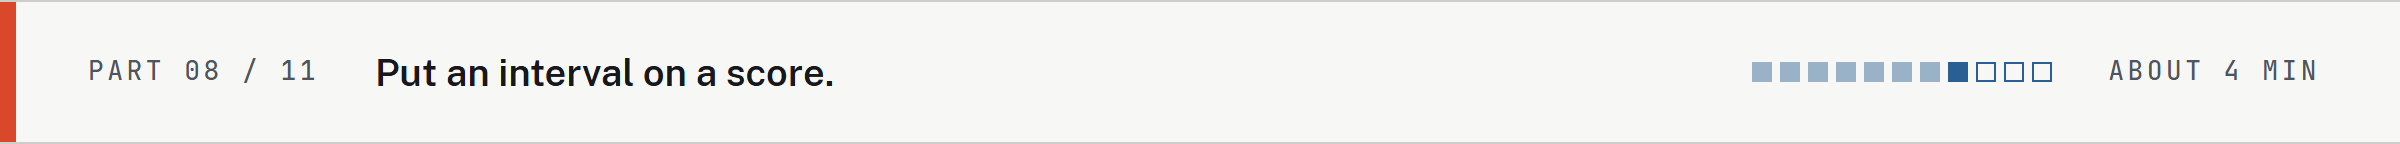

# How Sure Are We?

A score computed on 512 positives would come out differently on another sample.
The **bootstrap** imitates another sample: it draws from the data with replacement, computes the score again, and repeats.

The middle 95% of 1,000 such scores is the interval.

The rows here are not independent, because a company gives several rows and a failing company often gives two positives.
So the casebook draws whole companies, which is the **cluster bootstrap** that Chapter 3 borrowed.

Q. How does the library draw companies?

In [17]:
# taught: corp_default.metrics.cluster_bootstrap_ci
def company_resamples(y_true: np.ndarray, groups, n_boot: int, seed: int) -> Iterator[np.ndarray]:
    """Row indices of each usable company resample, in the published notebook's draw order.

    A resample with no positive or no negative is skipped; the caller counts what it receives.
    """
    rng = np.random.default_rng(seed)
    groups = np.asarray(groups)
    unique = np.unique(groups)
    index_of = pd.Series(np.arange(len(groups))).groupby(groups).indices
    for _ in range(n_boot):
        drawn = rng.choice(unique, size=len(unique), replace=True)
        idx = np.concatenate([index_of[g] for g in drawn])
        positives = y_true[idx].sum()
        if 0 < positives < len(idx):
            yield idx


def _interval(stats: list[float], n_boot: int) -> tuple[float, float, int]:
    if not stats:
        raise ValueError(
            f"no usable resample in {n_boot}: every one lacked a positive or a negative"
        )
    return float(np.percentile(stats, 2.5)), float(np.percentile(stats, 97.5)), len(stats)


def cluster_bootstrap_ci(
    y_true, scores, groups, metric, n_boot=1000, seed=42
) -> tuple[float, float, int]:
    """95% interval of `metric` resampling whole companies, and how many resamples were usable."""
    y_true, scores = np.asarray(y_true), np.asarray(scores)
    stats = [
        metric(y_true[idx], scores[idx]) for idx in company_resamples(y_true, groups, n_boot, seed)
    ]
    return _interval(stats, n_boot)

To compare two scores, the same draws serve both, and the difference is taken on each draw.
Much of the noise is shared by the two, and it cancels.

Q. How does the library compare two scores?

In [18]:
# taught: corp_default.metrics.paired_bootstrap_diff_ci
def paired_bootstrap_diff_ci(
    y_true, scores_a, scores_b, groups, metric, n_boot=1000, seed=42
) -> tuple[float, float, int]:
    """95% interval of metric(a) - metric(b) on the same company resamples, and the usable count."""
    y_true, scores_a, scores_b = np.asarray(y_true), np.asarray(scores_a), np.asarray(scores_b)
    diffs = [
        metric(y_true[idx], scores_a[idx]) - metric(y_true[idx], scores_b[idx])
        for idx in company_resamples(y_true, groups, n_boot, seed)
    ]
    return _interval(diffs, n_boot)

The second score is another single ratio from Chapter 3, market value over liabilities, turned over so that high means risky.

Q. How wide are the intervals, and is market value better than leverage?

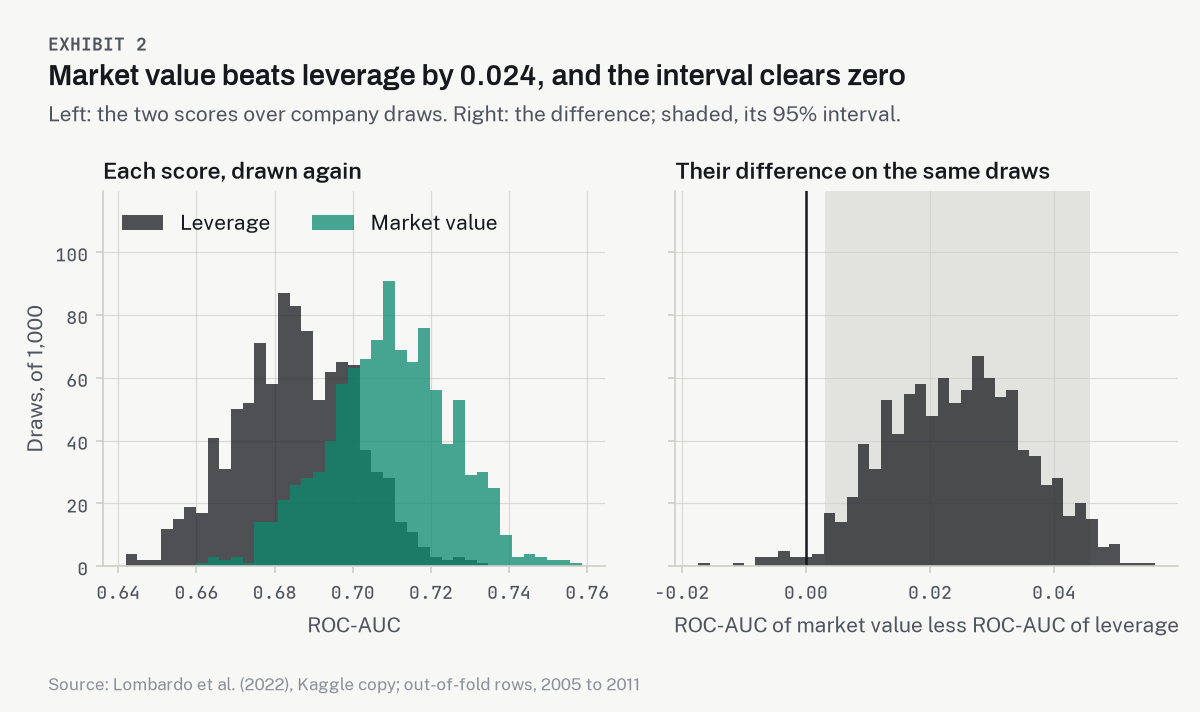

In [19]:
N_BOOT = 1000
market = walk_forward_oof(lambda train, valid: -valid["mve_to_liabilities"], dev, folds)
assert market[KEYS].equals(leverage[KEYS])
other, groups = market["pct"].to_numpy(), leverage["company_name"]

rng = np.random.default_rng(SEED)
by_rows = [
    roc_auc_score(y[idx], pct[idx])
    for idx in (rng.integers(len(y), size=len(y)) for _ in range(N_BOOT))
]
draws = pd.DataFrame(
    [
        {
            "Leverage": roc_auc_score(y[idx], pct[idx]),
            "Market value": roc_auc_score(y[idx], other[idx]),
        }
        for idx in company_resamples(y, groups, N_BOOT, SEED)
    ]
)
draws["difference"] = draws["Market value"] - draws["Leverage"]
row_low, row_high = np.percentile(by_rows, [2.5, 97.5])
cluster_low, cluster_high = np.percentile(draws["Leverage"], [2.5, 97.5])
diff = roc_auc_score(y, other) - roc_auc_score(y, pct)
diff_low, diff_high, _ = paired_bootstrap_diff_ci(y, other, pct, groups, roc_auc_score)
# The draws in the chart are the library's draws, and the title says the interval clears zero.
assert np.isclose(diff_low, np.percentile(draws["difference"], 2.5)) and diff_low > 0

store.put("n_boot", N_BOOT)
store.put("row_low", row_low)
store.put("row_high", row_high)
store.put("cluster_low", cluster_low)
store.put("cluster_high", cluster_high)
store.put("wider", (cluster_high - cluster_low) / (row_high - row_low) - 1)
store.put("row_width", row_high - row_low)
store.put("cluster_width", cluster_high - cluster_low)
store.put("market_auc", roc_auc_score(y, other))
store.put("diff", diff)
store.put("diff_low", diff_low)
store.put("diff_high", diff_high)

fig, (both, gap) = plt.subplots(1, 2, figsize=(viz.EXHIBIT_WIDTH_IN, 3.4), sharey=True)
bins = np.linspace(draws[["Leverage", "Market value"]].min().min(), draws[["Leverage", "Market value"]].max().max(), 40)  # fmt: skip
both.hist(draws["Leverage"], bins=bins, color=viz.INK, alpha=0.75, label="Leverage")
both.hist(draws["Market value"], bins=bins, color=viz.ACCENT, alpha=0.75, label="Market value")
both.set_title("Each score, drawn again")
both.set_xlabel("ROC-AUC")
both.set_ylabel(f"Draws, of {N_BOOT:,}")
both.set_ylim(0, both.get_ylim()[1] * 1.25)
both.legend(loc="upper left", ncols=2)
gap.hist(draws["difference"], bins=40, color=viz.INK, alpha=0.75)
gap.axvline(0, color=viz.INK, linewidth=1.2)
gap.xaxis.set_major_locator(MaxNLocator(5))
gap.axvspan(diff_low, diff_high, color=viz.RULE, alpha=0.5, linewidth=0, zorder=0)
gap.set_title("Their difference on the same draws")
gap.set_xlabel("ROC-AUC of market value less ROC-AUC of leverage")
viz.exhibit(
    fig,
    f"Market value beats leverage by {diff:.3f}, and the interval clears zero",
    "Left: the two scores over company draws. Right: the difference; shaded, its 95% interval.",
    OOF_SOURCE,
)

**Reading.** Drawn by rows, the interval for leverage runs from 0.660 to 0.710.
Drawn by companies it runs from 0.655 to 0.715, which is 20% wider.

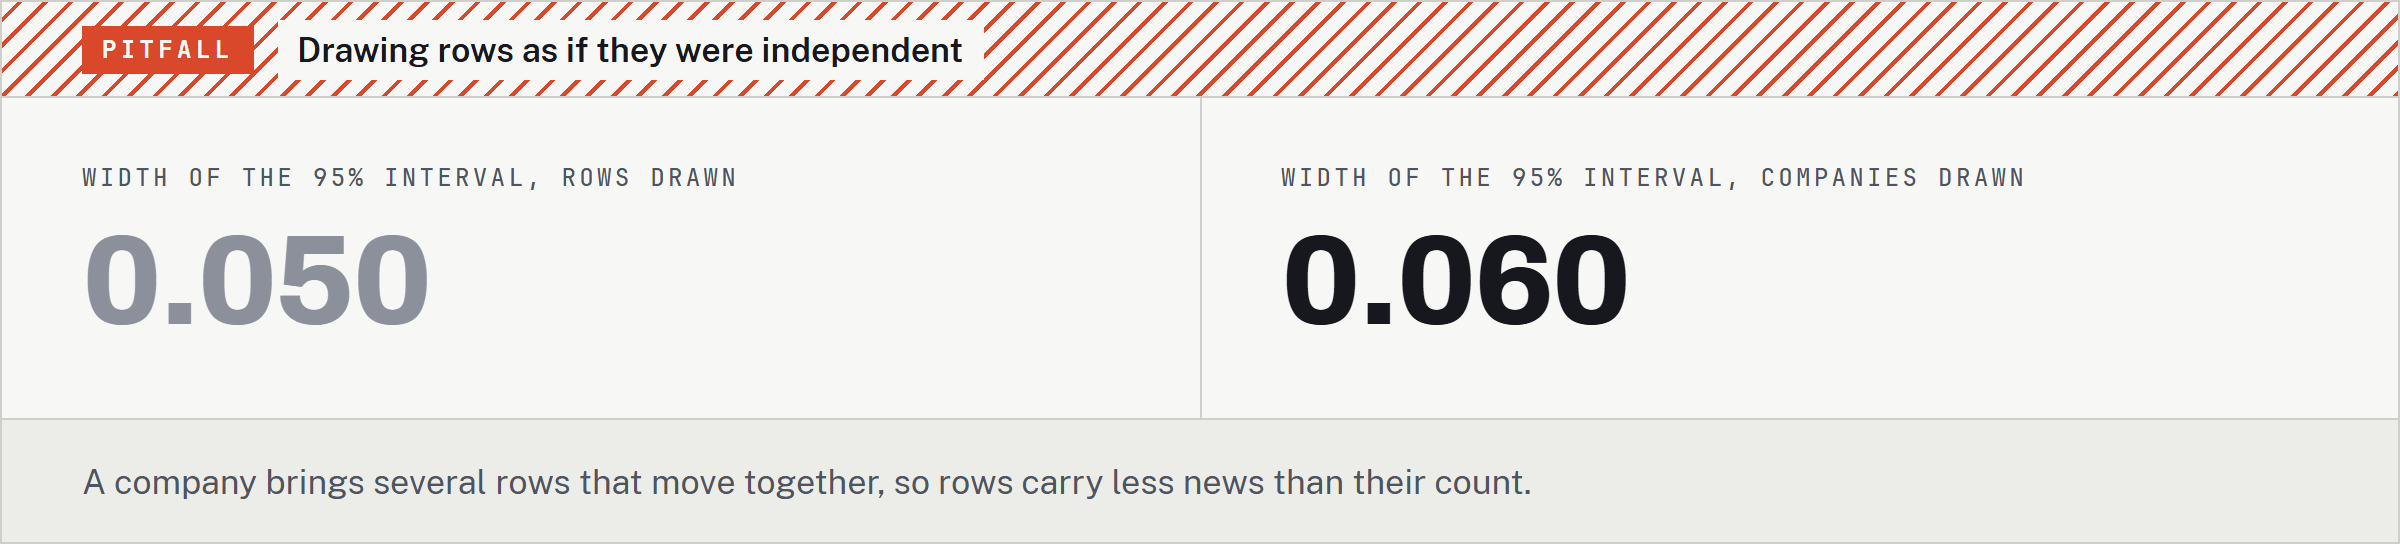

Market value scores 0.709 against 0.686, and in the left panel of Exhibit 2 the two heaps overlap.
That is the wrong test.

The right panel takes the difference on each draw: 0.024, with an interval from 0.003 to 0.046.
It clears zero, so the gain is real, and it is small.

**Next, the yardstick meets its first model.**

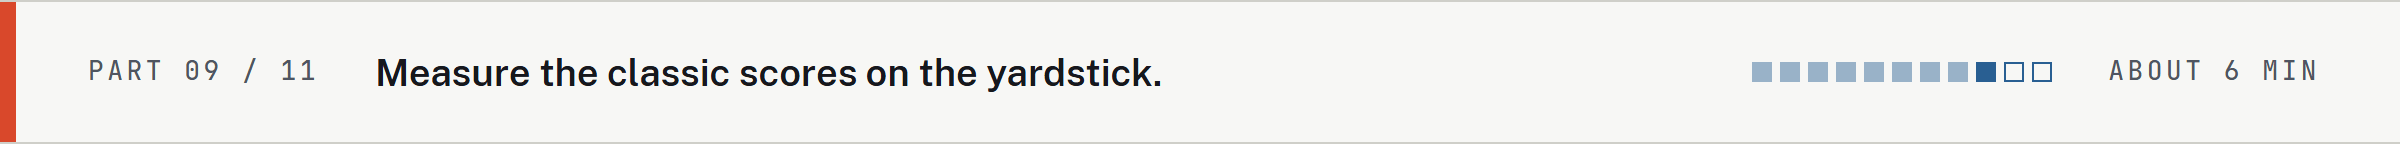

# Altman's Z

The best-known default score is the Z-score of [Altman (1968)](https://doi.org/10.1111/j.1540-6261.1968.tb00843.x).
It adds up five ratios, with weights fitted to 66 manufacturers.

Q. How does the library compute it?

In [20]:
# taught: corp_default.classic.altman_z
def altman_z(frame: pd.DataFrame) -> pd.Series:
    """Altman (1968) Z for public manufacturers, on the ratio columns of features.add_ratios.

    Z = 1.2 X1 + 1.4 X2 + 3.3 X3 + 0.6 X4 + 1.0 X5, with X1 working capital, X2 retained
    earnings, X3 EBIT, and X5 sales, each over total assets, and X4 market value of equity over
    total liabilities. Source: Altman (2000), pp. 9 and 13, in SOURCES.md.
    """
    return (
        1.2 * frame["working_capital_to_assets"]
        + 1.4 * frame["retained_earnings_to_assets"]
        + 3.3 * frame["ebit_to_assets"]
        + 0.6 * frame["mve_to_liabilities"]
        + 1.0 * frame["asset_turnover"]
    )

A high Z is safe.
Altman's **zones** call a company distressed below 1.81 and safe above 2.99, with a gray zone between.

Q. How often does a firm-year in each zone fail, among manufacturers and among the rest?

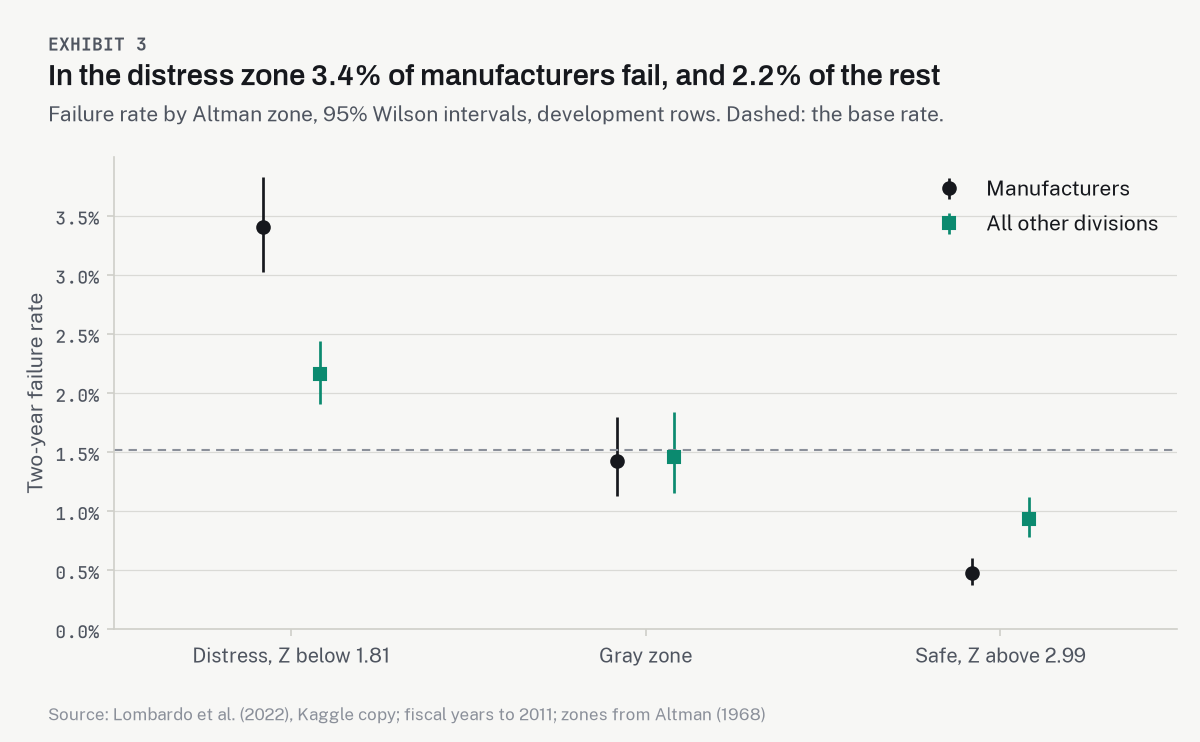

In [21]:
ALTMAN_SAMPLE = 66  # the manufacturers of the 1968 study; see SOURCES.md
ZONES = ["distress", "gray", "safe"]

zone = altman_zone(altman_z(dev))
maker = pd.Series(np.where(dev["division"] == "D", "Manufacturers", "All other divisions"))
by_zone = dev.groupby([maker, zone])["target"].agg(positives="sum", rows="size")
by_zone["rate"] = by_zone["positives"] / by_zone["rows"]
bounds = [wilson_interval(int(k), int(n)) for k, n in zip(by_zone["positives"], by_zone["rows"])]
by_zone = by_zone.join(pd.DataFrame(bounds, index=by_zone.index, columns=["low", "high"]))
every = dev.groupby(zone)["target"].mean()

store.put("altman_sample", ALTMAN_SAMPLE)
store.put("zone_distress", ALTMAN_ZONES["distress_below"])
store.put("zone_safe", ALTMAN_ZONES["safe_above"])
store.put("distress_rate", every.loc["distress"])
store.put("safe_rate", every.loc["safe"])
store.put("maker_distress", by_zone.loc[("Manufacturers", "distress"), "rate"])
store.put("maker_safe", by_zone.loc[("Manufacturers", "safe"), "rate"])
store.put("other_distress", by_zone.loc[("All other divisions", "distress"), "rate"])
store.put("other_safe", by_zone.loc[("All other divisions", "safe"), "rate"])
store.put("maker_share", (dev["division"] == "D").mean())

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.6))
place = np.arange(len(ZONES))
for group, color, marker, nudge in (
    ("Manufacturers", viz.INK, "o", -0.08),
    ("All other divisions", viz.ACCENT, "s", 0.08),
):
    table = by_zone.loc[group].loc[ZONES]
    ax.errorbar(place + nudge, table["rate"], yerr=[table["rate"] - table["low"], table["high"] - table["rate"]],
                fmt=marker, color=color, markersize=6, linewidth=1.3, label=group)  # fmt: skip
ax.axhline(dev["target"].mean(), color=viz.MIST, linewidth=1, linestyle=(0, (4, 3)))
ax.set_xticks(
    place,
    [
        f"Distress, Z below {ALTMAN_ZONES['distress_below']}",
        "Gray zone",
        f"Safe, Z above {ALTMAN_ZONES['safe_above']}",
    ],
)
ax.set_xlim(-0.5, len(ZONES) - 0.5)
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
ax.grid(axis="x", visible=False)
ax.set_ylabel("Two-year failure rate")
ax.legend(loc="upper right")
viz.exhibit(
    fig,
    f"In the distress zone {by_zone.loc[('Manufacturers', 'distress'), 'rate']:.1%} of manufacturers "
    f"fail, and {by_zone.loc[('All other divisions', 'distress'), 'rate']:.1%} of the rest",
    "Failure rate by Altman zone, 95% Wilson intervals, development rows. Dashed: the base rate.",
    f"{SOURCE}; fiscal years to {DEV_END}; zones from Altman (1968)",
)

**Reading.** In Exhibit 3 the zones are in the right order: 2.7% of the firm-years in the distress zone fail, and 0.7% of those in the safe zone.

The score was built on manufacturers, who are 48% of these rows, and it sorts them more sharply.
Their rates run from 3.4% down to 0.5%, where the rest run from 2.2% to 0.9%.

Q. How well does Z rank out of fold?

In [22]:
z_oof = walk_forward_oof(lambda train, valid: -altman_z(valid), dev, folds)
z2_oof = walk_forward_oof(lambda train, valid: -altman_z2(valid), dev, folds)
division_of = dev.drop_duplicates("company_name").set_index("company_name")["division"]
makers = (z_oof["company_name"].map(division_of) == "D").to_numpy()


def auc_with_interval(oof: pd.DataFrame) -> dict:
    """ROC-AUC of an out-of-fold table on its percentiles, with a cluster-bootstrap interval."""
    low, high, _ = cluster_bootstrap_ci(
        oof["target"], oof["pct"], oof["company_name"], roc_auc_score
    )
    return {
        "rows": len(oof),
        "positives": int(oof["target"].sum()),
        "ROC-AUC": roc_auc_score(oof["target"], oof["pct"]),
        "low": low,
        "high": high,
    }


classics = pd.DataFrame(
    {
        "Z, every division": auc_with_interval(z_oof),
        "Z, manufacturers": auc_with_interval(z_oof.loc[makers]),
        "Z, all other divisions": auc_with_interval(z_oof.loc[~makers]),
        "Z'', every division": auc_with_interval(z2_oof),
    }
).T.astype({"rows": int, "positives": int})

store.put("z_auc", classics.loc["Z, every division", "ROC-AUC"])
store.put("z_makers", classics.loc["Z, manufacturers", "ROC-AUC"])
# The reading says the two intervals overlap, and only just. Checked here.
assert (
    0
    < classics.loc["Z, all other divisions", "high"] - classics.loc["Z, manufacturers", "low"]
    < 0.02
)
store.put("z_makers_low", classics.loc["Z, manufacturers", "low"])
store.put("z_others", classics.loc["Z, all other divisions", "ROC-AUC"])
store.put("z_others_high", classics.loc["Z, all other divisions", "high"])
store.put("z2_auc", classics.loc["Z'', every division", "ROC-AUC"])

classics.round(3)

,rows,positives,ROC-AUC,low,high
"Z, every division",26789,512,0.704,0.678,0.728
"Z, manufacturers",13237,249,0.737,0.701,0.771
"Z, all other divisions",13552,263,0.671,0.635,0.710
"Z'', every division",26789,512,0.702,0.676,0.725


**Reading.** Z has a ROC-AUC of 0.704, a little above leverage alone.
Among manufacturers it scores 0.737 and among the rest 0.671.

The lower end of the first interval, 0.701, is just below the upper end of the second, 0.710, so the two barely overlap.
So Z very likely ranks better where it was built, and the file cannot quite prove it.

Z'' is Altman's later form for companies that are not manufacturers: it drops the sales ratio and uses book equity.
It scores 0.702, no better.

A third classic, the score of Zmijewski, is left out, because its weights could not be checked against the paper for `SOURCES.md`.

Q. Where on the ranking does Z go wrong?

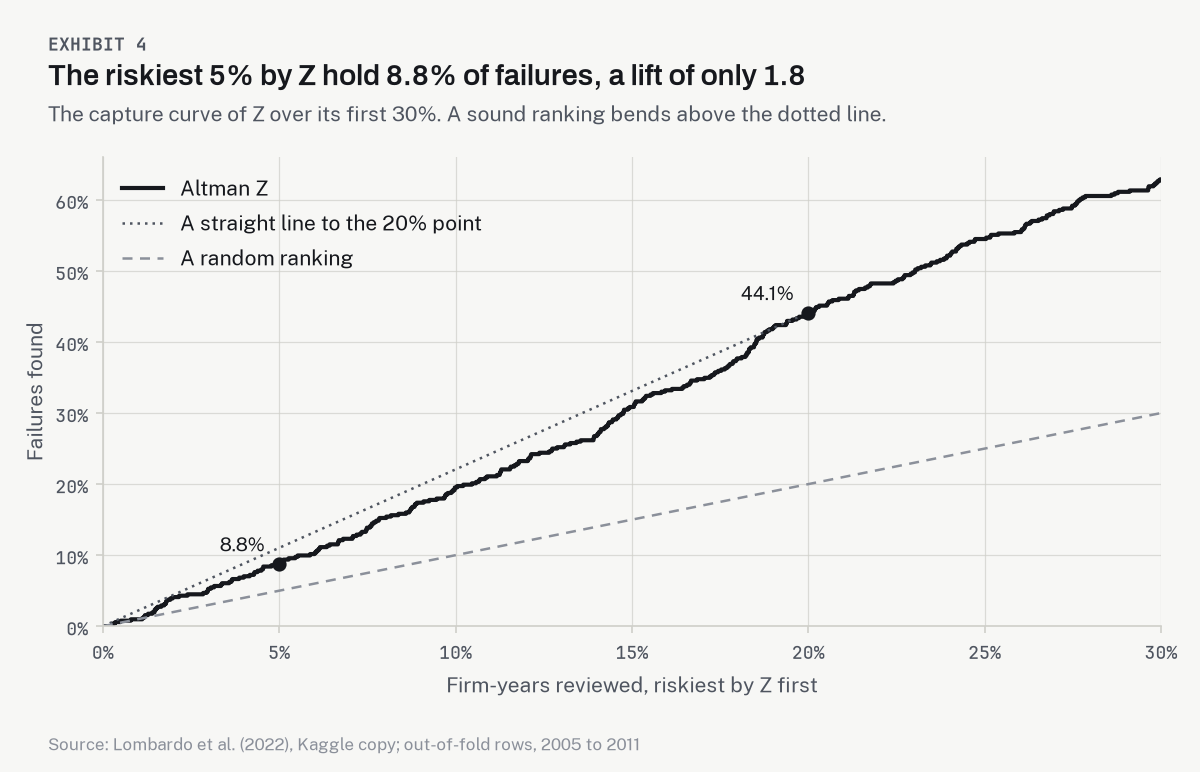

In [23]:
z_y, z_pct = z_oof["target"].to_numpy(), z_oof["pct"].to_numpy()
z_reviewed, z_captured = capture_curve(z_y, z_pct)
TOP, WIDER = 0.05, 0.20  # the first slice of the ranking, and a wider one to compare it with
at_top, at_wider = (z_captured[round(share * len(z_y))] for share in (TOP, WIDER))
lift_top = at_top / TOP
lift_next = (at_wider - at_top) / (WIDER - TOP)
# The title and the reading say the ranking is steeper after its first slice. Checked here.
assert lift_next > lift_top

store.put("z_top", TOP)
store.put("z_next", WIDER - TOP)
store.put("z_capture_top", at_top)
store.put("z_lift_top", lift_top)
store.put("z_capture_next", at_wider - at_top)
store.put("z_lift_next", lift_next)

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.8))
ax.plot(z_reviewed, z_captured, color=viz.INK, label="Altman Z")
ax.plot([0, WIDER], [0, at_wider], color=viz.SLATE, linewidth=1.2, linestyle=(0, (1, 2)),
        label=f"A straight line to the {WIDER:.0%} point")  # fmt: skip
ax.plot(
    [0, 1], [0, 1], color=viz.MIST, linewidth=1.2, linestyle=(0, (4, 3)), label="A random ranking"
)
for share, found in ((TOP, at_top), (WIDER, at_wider)):
    ax.scatter(share, found, s=34, color=viz.INK, zorder=3)
    ax.annotate(f"{found:.1%}", (share, found), xytext=(-7, 6), textcoords="offset points",
                ha="right", size=9)  # fmt: skip
ax.set_xlim(0, 0.3)
ax.set_ylim(0, z_captured[round(0.3 * len(z_y))] * 1.05)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Firm-years reviewed, riskiest by Z first")
ax.set_ylabel("Failures found")
ax.legend(loc="upper left")
viz.exhibit(
    fig,
    f"The riskiest {TOP:.0%} by Z hold {at_top:.1%} of failures, a lift of only {lift_top:.1f}",
    "The capture curve of Z over its first 30%. A sound ranking bends above the dotted line.",
    OOF_SOURCE,
)

**Reading.** In Exhibit 4 the curve of Z starts below the dotted line and crosses above it later.
The riskiest 5% by Z hold 8.8% of the failures, a lift of 1.8.

The next 15% hold 35%, a lift of 2.4.
A sound ranking is steepest at its start, and this one is steeper later.

It is the flat weak end of Chapter 3, seen from the desk.
At the same budget leverage alone finds 12.5%.

**Next, whether new weights mend it.**

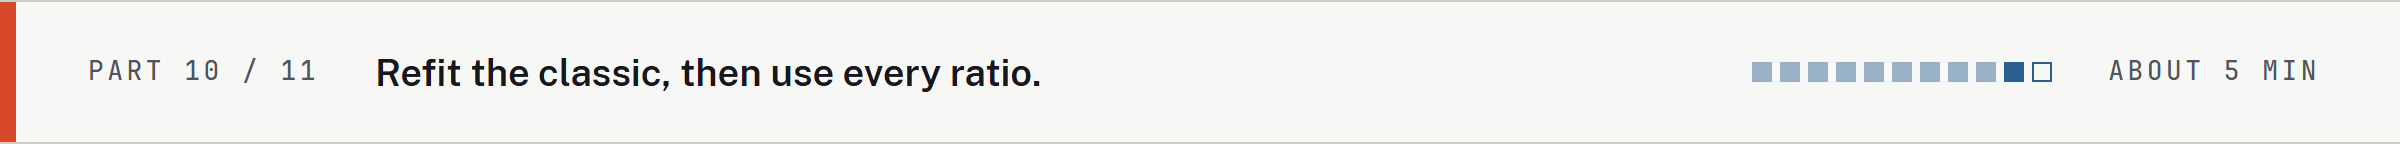

# Refitting Z

Z is old, and two things in it could be out of date: the weights, or the choice of five ratios.
A refit tests the first.

It keeps the five ratios and fits new weights to this data with a **logistic regression**, a model that adds up weighted inputs and turns the sum into a probability.

**Predict 2.** Will the refitted weights rank better out of fold than the published ones?

Five weights on five scales cannot be compared as they stand.
A weight's **pull** is the weight times the standard deviation of its ratio, taken as a share of the five.

Q. How do the refitted weights compare with the published ones?

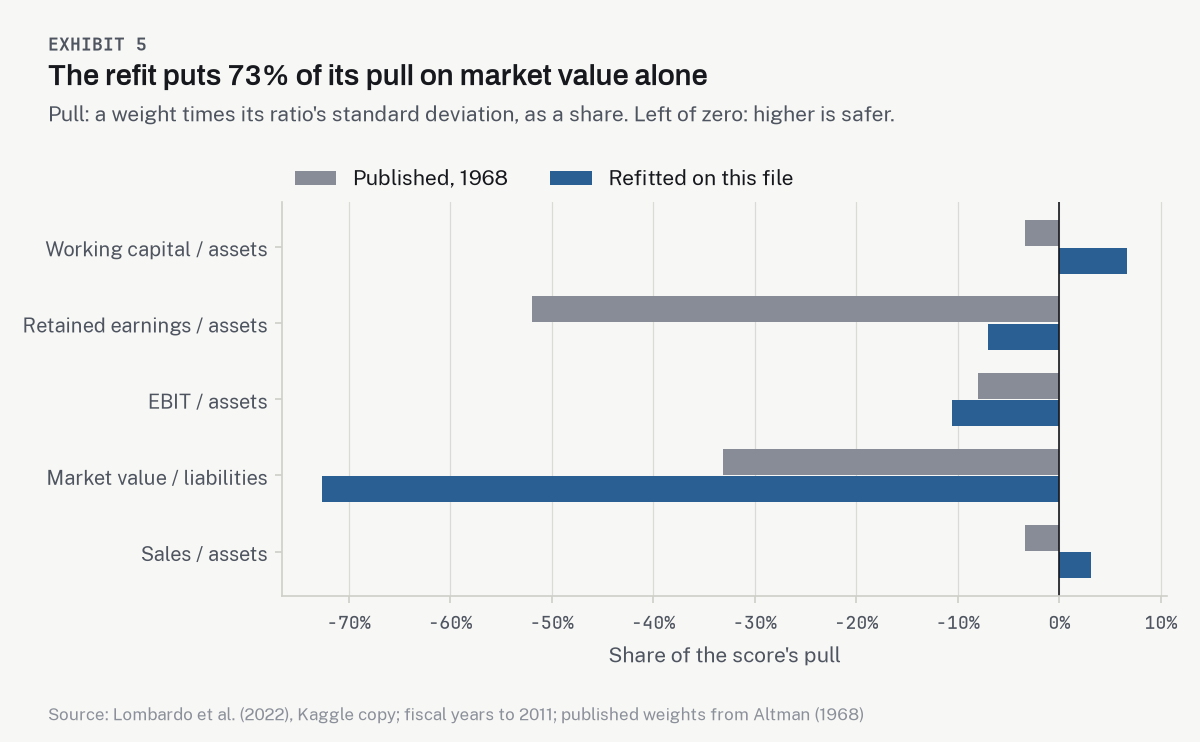

In [24]:
PUBLISHED = pd.Series(  # the weights in altman_z above
    {
        "working_capital_to_assets": 1.2,
        "retained_earnings_to_assets": 1.4,
        "ebit_to_assets": 3.3,
        "mve_to_liabilities": 0.6,
        "asset_turnover": 1.0,
    }
)
FIVE = list(PUBLISHED.index)


def logistic(columns: list[str], C: float):
    """A walk-forward recipe: clip, fill, and standardize on the training rows, then fit."""

    def fit_predict(train: pd.DataFrame, valid: pd.DataFrame) -> np.ndarray:
        prepare, *_ = fit_prepare(train, columns)
        model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
        model.fit(prepare(train), train["target"])
        return model.predict_proba(prepare(valid))[:, 1]

    return fit_predict


refit_oof = walk_forward_oof(logistic(FIVE, np.inf), dev, folds)  # C of infinity: no penalty


def auc_by_fold(oof: pd.DataFrame) -> pd.Series:
    return oof.groupby("year").apply(lambda rows: roc_auc_score(rows["target"], rows["pct"]),
                                     include_groups=False)  # fmt: skip


# The weights themselves, from one fit on every development row.
# Each is multiplied by its ratio's standard deviation, so the five can be compared.
prepare, *_ = fit_prepare(dev, FIVE)
inputs = prepare(dev)
refit = LogisticRegression(C=np.inf, max_iter=5000).fit(inputs, dev["target"])
pull = pd.DataFrame(
    {
        "Published": -PUBLISHED * inputs.std(),  # Z counts safety, so its sign is turned
        "Refitted": pd.Series(refit.coef_[0], index=FIVE) * inputs.std(),
    }
)
share = pull / pull.abs().sum()
# The reading says the refit gives two ratios the opposite sign. Checked here.
assert (share["Refitted"] > 0).sum() == 2 and (share["Published"] < 0).all()

store.put("refit_auc", roc_auc_score(refit_oof["target"], refit_oof["pct"]))
store.put("refit_folds_ahead", int((auc_by_fold(refit_oof) > auc_by_fold(z_oof)).sum()))
store.put("published_retained", -share.loc["retained_earnings_to_assets", "Published"])
store.put("published_market", -share.loc["mve_to_liabilities", "Published"])
store.put("refit_market", -share.loc["mve_to_liabilities", "Refitted"])
store.put("refit_retained", -share.loc["retained_earnings_to_assets", "Refitted"])

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.6))
place = np.arange(len(FIVE))
ax.barh(place - 0.18, share["Published"], height=0.34, color=viz.MODEL_COLORS["classic"],
        label="Published, 1968")  # fmt: skip
ax.barh(place + 0.18, share["Refitted"], height=0.34, color=viz.MODEL_COLORS["logistic"],
        label="Refitted on this file")  # fmt: skip
ax.axvline(0, color=viz.INK, linewidth=0.8)
ax.set_yticks(place, [viz.label(name) for name in FIVE])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of the score's pull")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1), ncols=2, borderaxespad=0.2)
viz.exhibit(
    fig,
    f"The refit puts {-share.loc['mve_to_liabilities', 'Refitted']:.0%} of its pull on market value alone",
    "Pull: a weight times its ratio's standard deviation, as a share. Left of zero: higher is safer.",
    f"{SOURCE}; fiscal years to {DEV_END}; published weights from Altman (1968)",
)

**Reading.** The refit scores 0.662 out of fold, below the 0.704 of the published weights, and it is ahead in 1 of the 7 folds.
New weights, fitted to the ratios as they stand, do not mend Z, and a check at the end of the chapter shows why.

Exhibit 5 shows how the two differ.
Altman's weights put 52% of the pull on retained earnings and 33% on market value.

The refit puts 73% on market value and 7% on retained earnings, and it turns the sign of working capital and of sales.
It leans on one ratio where Altman spread the weight over two, and out of fold that serves it worse.

Two suspects are left: the scale the ratios are fitted on, and the choice of ratios.
The ladder takes the choice first, and the scale is tested after it.

The next model takes all 24, many of them near copies of each other, so it needs a **penalty** that shrinks the weights toward zero.

The strength of the penalty is a setting, `C`, and a smaller `C` is a stronger penalty.
The rule for choosing it is fixed before any result is seen.

- Take the `C` with the highest mean average precision over the 7 folds, each fold counting the same.
- If two are level, take the stronger penalty.

Q. Which strength does the rule choose?

In [25]:
GRID = [0.001, 0.01, 0.1, 1.0, 10.0]
candidates = {C: walk_forward_oof(logistic(RATIOS, C), dev, folds) for C in GRID}
by_strength = pd.DataFrame(
    {
        C: oof.groupby("year").apply(
            lambda rows: average_precision_score(rows["target"], rows["score"]),
            include_groups=False,
        )
        for C, oof in candidates.items()
    }
)
by_strength.columns.name = "C"
means = by_strength.mean()
chosen = float(means.idxmax())  # idxmax returns the first, which is the stronger penalty on a tie

store.put("chosen_c", chosen)
store.put("chosen_ap", means.max())
store.put("runner_up_ap", means.sort_values().iloc[-2])
store.put("grid_size", len(GRID))

by_strength.loc["mean"] = means
by_strength.round(4)

C,0.001,0.010,0.100,1.000,10.000
year,,,,,
2005,0.0521,0.0574,0.0647,0.0651,0.0680
2006,0.0632,0.0660,0.0700,0.0710,0.0695
2007,0.0538,0.0564,0.0569,0.0581,0.0583
2008,0.0482,0.0705,0.0624,0.0465,0.0460
2009,0.0400,0.0407,0.0382,0.0367,0.0362
2010,0.0450,0.0525,0.0525,0.0541,0.0575
2011,0.0376,0.0461,0.0498,0.0509,0.0514
mean,0.0486,0.0556,0.0564,0.0547,0.0553


**Reading.** The rule chooses a `C` of 0.1, with a mean average precision of 0.0564.
The runner-up among the 5 settings scores 0.0556, so near the top the choice matters little.

**Next, the three models side by side.**

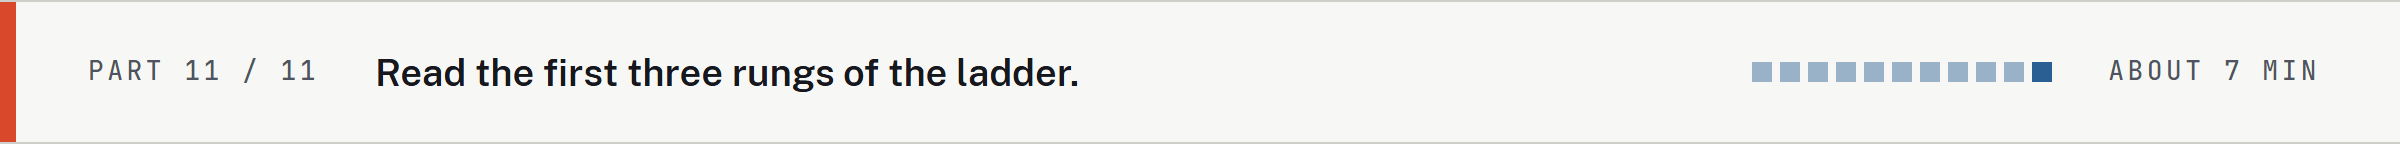

# The Scoreboard So Far

Three models now stand on the same 26,789 out-of-fold rows:

- Altman's Z, with its published weights;
- Altman's five ratios, refitted;
- all 24 ratios in a penalized logistic regression.

They are the first three rungs of the **ladder**, the exhibit this casebook is built around.
Each rung is compared with the rung below it on the same draws of companies.

The next three cells draw the companies 1,000 times each, and each takes a minute or so.

Q. How do the three score?

In [26]:
rungs = {
    "Altman Z": z_oof,
    "Five ratios, refitted": refit_oof,
    "All ratios, logistic": candidates[chosen],
}
board = scoreboard(rungs, n_boot=N_BOOT).set_index("model")

top_rung = board.loc["All ratios, logistic"]
store.put("all_auc", top_rung["roc_auc"])
store.put("all_auc_low", top_rung["roc_auc_lo"])
store.put("all_auc_high", top_rung["roc_auc_hi"])
store.put("all_capture_5", top_rung["capture_5"])
store.put("z_capture_5", board.loc["Altman Z", "capture_5"])

board[["roc_auc", "roc_auc_lo", "roc_auc_hi", "ap", "capture_5", "lift_5", "accuracy_ratio"]].round(
    3
)

,roc_auc,roc_auc_lo,roc_auc_hi,ap,capture_5,lift_5,accuracy_ratio
model,,,,,,,
Altman Z,0.704,0.678,0.728,0.035,0.088,1.758,0.409
"Five ratios, refitted",0.662,0.634,0.692,0.033,0.086,1.719,0.325
"All ratios, logistic",0.750,0.728,0.773,0.051,0.170,3.400,0.500


**Reading.** The model on all ratios has a ROC-AUC of 0.750, with an interval from 0.728 to 0.773.
At the middle budget it finds 17.0% of the failures, where Z finds 8.8%.

Q. What does each rung add to the one below it?

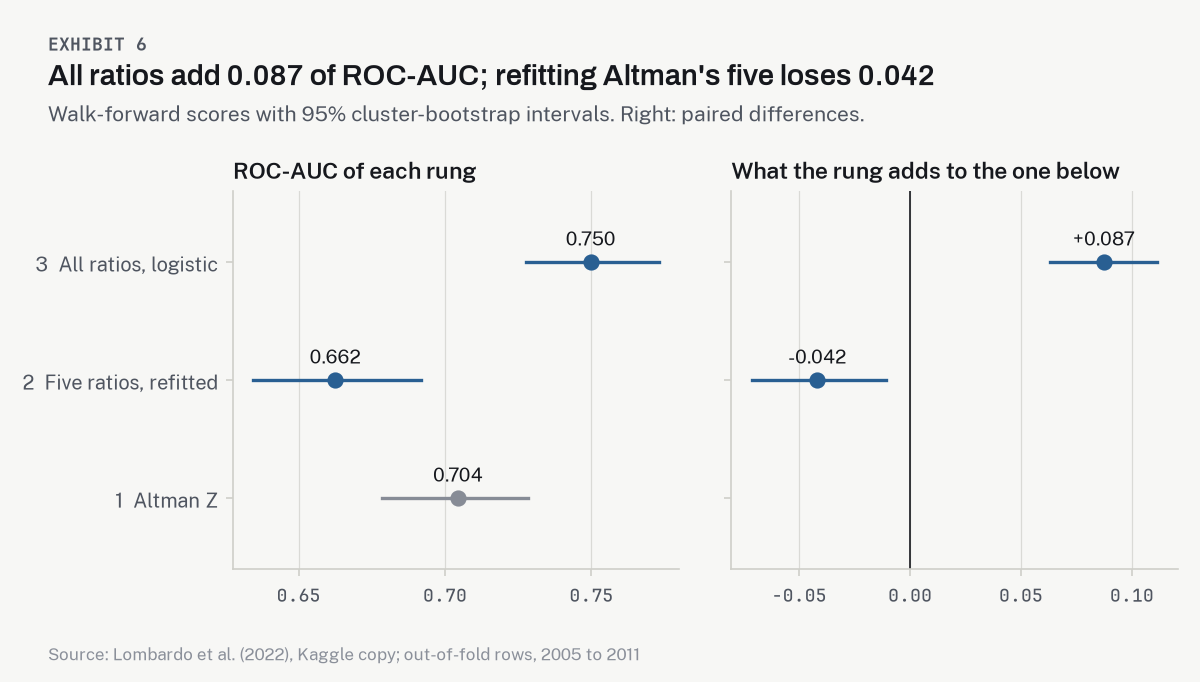

In [27]:
steps = paired_table(rungs, list(rungs), n_boot=N_BOOT).set_index("model")
refit_step, all_step = steps.loc["Five ratios, refitted"], steps.loc["All ratios, logistic"]
# The title and the reading say the first step is a loss and the second a gain, both clear of zero.
assert refit_step["roc_auc_diff_hi"] < 0 < all_step["roc_auc_diff_lo"]

store.put("refit_step", refit_step["roc_auc_diff"])
store.put("refit_step_low", refit_step["roc_auc_diff_lo"])
store.put("refit_step_high", refit_step["roc_auc_diff_hi"])
store.put("all_step", all_step["roc_auc_diff"])
store.put("all_step_low", all_step["roc_auc_diff_lo"])
store.put("all_step_high", all_step["roc_auc_diff_hi"])

COLORS = [viz.MODEL_COLORS["classic"], viz.MODEL_COLORS["logistic"], viz.MODEL_COLORS["logistic"]]
fig, (level, step) = plt.subplots(1, 2, figsize=(viz.EXHIBIT_WIDTH_IN, 3.2), sharey=True)
place = np.arange(len(rungs))
for y_at, (name, row), color in zip(place, board.iterrows(), COLORS):
    level.plot([row["roc_auc_lo"], row["roc_auc_hi"]], [y_at, y_at], color=color, linewidth=1.6)
    level.scatter(row["roc_auc"], y_at, s=46, color=color, zorder=3)
    level.annotate(f"{row['roc_auc']:.3f}", (row["roc_auc"], y_at), xytext=(0, 8),
                   textcoords="offset points", ha="center", size=9)  # fmt: skip
for y_at, (name, row), color in zip(place[1:], steps.iterrows(), COLORS[1:]):
    step.plot([row["roc_auc_diff_lo"], row["roc_auc_diff_hi"]], [y_at, y_at], color=color,
              linewidth=1.6)  # fmt: skip
    step.scatter(row["roc_auc_diff"], y_at, s=46, color=color, zorder=3)
    step.annotate(f"{row['roc_auc_diff']:+.3f}", (row["roc_auc_diff"], y_at), xytext=(0, 8),
                  textcoords="offset points", ha="center", size=9)  # fmt: skip
step.axvline(0, color=viz.INK, linewidth=0.8)
level.set_yticks(place, [f"{k + 1}  {name}" for k, name in enumerate(rungs)])
level.set_ylim(-0.6, len(rungs) - 0.4)
level.set_title("ROC-AUC of each rung")
level.xaxis.set_major_locator(MultipleLocator(0.05))
step.set_title("What the rung adds to the one below")
for ax in (level, step):
    ax.grid(axis="y", visible=False)
viz.exhibit(
    fig,
    f"All ratios add {all_step['roc_auc_diff']:.3f} of ROC-AUC; refitting Altman's five loses "
    f"{-refit_step['roc_auc_diff']:.3f}",
    "Walk-forward scores with 95% cluster-bootstrap intervals. Right: paired differences.",
    OOF_SOURCE,
    save_as="ch4",
)

**Reading.** Exhibit 6 is the ladder so far.
The second rung is a step down: -0.042, with an interval from -0.071 to -0.011, which answers Predict 2.

The third rung is a step up of 0.087, with an interval from 0.063 to 0.111.
That step brings two changes together: more ratios, and size and market value on a log scale.

Q. Did the refit lose to Z for its weights, or for the scale of its ratios?

In [28]:
# The same five ratios, the same folds, and no penalty. Only the scale changes: each ratio is
# mapped to its rank among the training rows, then onto a normal curve, before the fit.
def rank_logistic(columns: list[str], C: float):
    def fit_predict(train: pd.DataFrame, valid: pd.DataFrame) -> np.ndarray:
        prepare, *_ = fit_prepare(train, columns)
        model = make_pipeline(
            QuantileTransformer(output_distribution="normal", random_state=SEED),
            LogisticRegression(C=C, max_iter=5000),
        )
        model.fit(prepare(train), train["target"])
        return model.predict_proba(prepare(valid))[:, 1]

    return fit_predict


rank_oof = walk_forward_oof(rank_logistic(FIVE, np.inf), dev, folds)
RANK = "Five ratios, rank scale"
rank_step = (
    paired_table({"Altman Z": z_oof, RANK: rank_oof}, ["Altman Z", RANK], n_boot=N_BOOT)
    .set_index("model")
    .loc[RANK]
)
# The reading says the rank-scale refit is ahead of Z with an interval above zero. Checked here.
assert rank_step["roc_auc_diff_lo"] > 0

store.put("rank_auc", roc_auc_score(rank_oof["target"], rank_oof["pct"]))
store.put("rank_step", rank_step["roc_auc_diff"])
store.put("rank_step_low", rank_step["roc_auc_diff_lo"])
store.put("rank_step_high", rank_step["roc_auc_diff_hi"])
rank_step[["roc_auc_diff", "roc_auc_diff_lo", "roc_auc_diff_hi"]].astype(float).round(3)

roc_auc_diff       0.028
roc_auc_diff_lo    0.003
roc_auc_diff_hi    0.053
Name: Five ratios, rank scale, dtype: float64

**Reading.** On a rank scale the same five ratios score 0.732, ahead of Z by 0.028, with an interval from 0.003 to 0.053.
So new weights can mend Z after all: the refit lost for its scale, since a few extreme ratios pull a straight-line fit on the raw values.

The second rung stays as built, because the ladder was fixed before this check.
Chapter 6 fits its networks on this same rank scale, and the trees of Chapter 5 do not depend on scale at all.

**Predict 3.** The crisis folds have more failures to find and less data to train on. Does the top rung rank better in them, or worse?

Q. Do the results hold fold by fold, and in the crisis?

In [29]:
# The library's table gives each fold and each pool its ROC-AUC with a bootstrap interval.
fold_tables = {
    name: fold_table(oof, n_boot=N_BOOT).set_index("fold") for name, oof in rungs.items()
}
folds_auc = pd.concat(
    {
        name: table[["roc_auc", "roc_auc_lo", "roc_auc_hi"]].set_axis(
            ["ROC-AUC", "low", "high"], axis=1
        )
        for name, table in fold_tables.items()
    },
    axis=1,
)
top_folds = fold_tables["All ratios, logistic"]
# The reading says the top rung is ahead of Z in every fold. Checked here.
assert (top_folds["roc_auc"] > fold_tables["Altman Z"]["roc_auc"]).all()

store.put("crisis_auc", top_folds.loc["crisis folds", "roc_auc"])
store.put("crisis_low", top_folds.loc["crisis folds", "roc_auc_lo"])
store.put("crisis_high", top_folds.loc["crisis folds", "roc_auc_hi"])
store.put("calm_auc", top_folds.loc["calm folds", "roc_auc"])
store.put("calm_low", top_folds.loc["calm folds", "roc_auc_lo"])
store.put("calm_high", top_folds.loc["calm folds", "roc_auc_hi"])

folds_auc.round(3)

Altman Z               Five ratios, refitted                \
              ROC-AUC    low   high               ROC-AUC    low   high   
fold                                                                      
2005            0.655  0.604  0.704                 0.661  0.605  0.715   
2006            0.721  0.680  0.764                 0.654  0.603  0.710   
2007            0.740  0.694  0.781                 0.698  0.643  0.754   
2008            0.674  0.617  0.739                 0.637  0.561  0.712   
2009            0.704  0.627  0.764                 0.637  0.564  0.704   
2010            0.748  0.680  0.807                 0.704  0.632  0.770   
2011            0.711  0.647  0.770                 0.652  0.572  0.723   
crisis folds    0.703  0.669  0.735                 0.668  0.629  0.704   
calm folds      0.707  0.666  0.744                 0.655  0.610  0.696   

             All ratios, logistic                
                          ROC-AUC    low   high  
fold                                             
2005                        0.702  0.653  0.750  
2006                        0.751  0.708  0.793  
2007                        0.780  0.728  0.826  
2008                        0.752  0.689  0.815  
2009                        0.735  0.672  0.794  
2010                        0.795  0.742  0.847  
2011                        0.775  0.709  0.837  
crisis folds                0.741  0.709  0.774  
calm folds                  0.762  0.728  0.798

**Reading.** The top rung is ahead of Z in every fold.
In the crisis folds it scores 0.741, with an interval from 0.709 to 0.774, and in the calm folds 0.762, from 0.728 to 0.798.

The two intervals overlap, so the file does not show that the model ranks worse under stress.
The crisis folds are also the ones with the least training data, and the two cannot be told apart here.

**Check.** Stress is when a model matters most. Why was `C` not chosen on the crisis folds alone?

<details>
<summary>Show the answer</summary>

A result that helped to make a choice stops being evidence about that choice.
The crisis folds are reported apart only because nothing was chosen on them alone.

They also hold fewer folds and so a noisier average, which is a poor guide to any setting.

</details>

Q. What does the chapter hand on?

In [30]:
oof_scores = pd.concat([oof.assign(model=name) for name, oof in rungs.items()], ignore_index=True)
frozen = {
    "Altman Z": {"kind": "published score", "features": FIVE},
    "Five ratios, refitted": {"kind": "logistic regression", "features": FIVE, "penalty": "none"},
    "All ratios, logistic": {
        "kind": "logistic regression",
        "features": RATIOS,
        "penalty": "l2",
        "C": chosen,
    },
}
store.save_frame("oof_scores", oof_scores)
store.save_json("frozen", frozen)

oof_scores.groupby("model")["target"].agg(rows="size", positives="sum")

,rows,positives
model,,
"All ratios, logistic",26789,512
Altman Z,26789,512
"Five ratios, refitted",26789,512


**Reading.** The out-of-fold scores of the three rungs are written, with the recipe of each.
Chapter 5 adds its rungs to the same rows, so every later comparison is paired with these.

**The next chapter asks what a model that bends, and one that remembers, can add.**

# Findings

1. A ranking by leverage alone finds 27% of the failures in the riskiest tenth of firm-years, a lift of 2.7, and almost nothing extra at the very top (Exhibit 1).
2. Drawing companies in place of rows widens the interval of a score by 20%, and a paired difference of 0.024 between two scores is clear of zero where their own intervals overlap (Exhibit 2).
3. Altman's zones are in the right order, and sharper for manufacturers: 3.4% of them fail in the distress zone, against 2.2% of the rest (Exhibit 3).
4. Z ranks with a ROC-AUC of 0.704 and goes wrong at its weak end: its riskiest 5% carry a lift of only 1.8 (Exhibit 4).
5. New weights fitted to the raw ratios do not mend Z: the refit scores 0.662, a step of -0.042, and it puts 73% of its pull on one ratio (Exhibit 5, Exhibit 6). On a rank scale the same five ratios are 0.028 ahead of Z, with an interval above zero, so the refit lost for its scale and not for having new weights.
6. All 24 ratios in a penalized logistic regression score 0.750, a step of 0.087 over the refit, and that step brings more ratios and a log scale for size together (Exhibit 6).

# Your Turn

Three extensions, each with a hint folded under it.

**1. Z'' where it belongs.** Z'' was made for companies that are not manufacturers. Does it beat Z among them?

<details>
<summary>Hint</summary>

Take `z_oof.loc[~makers]` and `z2_oof.loc[~makers]`, which hold the same rows.
Pass their `pct` columns to `paired_bootstrap_diff_ci` with `roc_auc_score`.

</details>

**2. A one-year embargo.** Build the folds with a gap of one year. How many validation positives belong to a company that is positive in the last training year?

<details>
<summary>Hint</summary>

Call `walk_forward_folds(dev, horizon=1)`.
For each fold, compare the companies of the positive validation rows with the companies positive in the last training year, as the embargo cell does.

</details>

**3. Another rule.** Choose `C` by mean ROC-AUC in place of mean average precision. Does the choice change?

<details>
<summary>Hint</summary>

Rebuild `by_strength` with `roc_auc_score` in place of `average_precision_score`.
Then compare the two rows of means.

</details>

[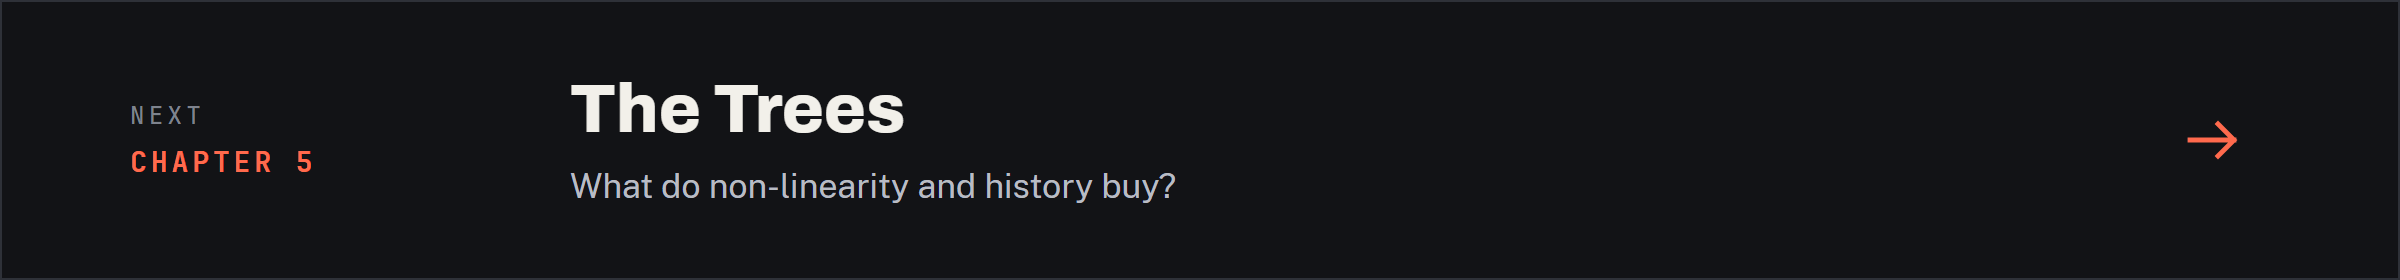](05_the_trees.ipynb)